# Merge the meteo products and overview (2004-2026.09)

**notebook version**: `6` (22 Oct 2026)

## ℹ️ About this notebook

The capstone of the `30_PRODUCTS` stage. It reads the per-variable products, joins them onto one
continuous 30MIN `TIMESTAMP_MID` index, writes a single merged file, and draws an overview figure
for each series.

Nothing is computed or corrected here. The values are exactly what the product notebooks exported,
so this notebook must run after them.

**This version covers 2004 to 30 September 2026 and merges notebooks `01` to `07`.** These are the
products extended to September 2026 so far. `08` to `13` still end in December 2025. Their entries
stay in the registry and are merged again as each notebook is extended. Notebook version `5` merged
all thirteen products over 2004-2025.

**Outputs:**

- `99_METEO_MERGED_2004-2026.09.parquet` / `.csv`: every merged value and its provenance flag in
  one wide table.
- `99_METEO_MERGED_2004-2026.09_INFO.md`: a plain-text description of that table, written beside it.
- One overview figure per series: daily time series, diurnal fingerprint, annual cycle, and the
  provenance flag composition per year (or the value distribution where a series carries no flag).

## 📇 Data sources

All inputs are the parquet products in the external data folder, written by earlier notebooks of
this stage. `SW_IN`, `TA` and `PPFD_IN` keep their `_gfXG` (gap-filled) columns. `RH` carries a
`_MISSING` flag, `LW_IN` a `_SOURCE` flag naming its calibration era, and `PA` no flag at all. `TA`,
`RH` and `VPD` each contribute **two** value columns and **two** flags.

| notebook | value column | flag column | span |
|---|---|---|---|
| `01` `SW_IN` | `SW_IN_T1_47_1_gfXG` | `FLAG_SW_IN_T1_47_1_ISFILLED` | 2004 - Sep 2026 |
| `02` `TA` | `TA_T1_47_1_gfXG` | `FLAG_TA_T1_47_1_ISFILLED` | 2004 - Sep 2026 |
| `02` `TA_HOM` | `TA_T1_47_1_HOMOGENIZED_gfXG` | `FLAG_TA_T1_47_1_SOURCE` | 2004 - Sep 2026 |
| `03` `PPFD_IN` | `PPFD_IN_T1_47_1_gfXG` | `FLAG_PPFD_IN_T1_47_1_ISFILLED` | 2004 - Sep 2026 |
| `04` `RH` | `RH_T1_47_1` | `FLAG_RH_T1_47_1_MISSING` | 2004 - Sep 2026 |
| `04` `RH_HOM` | `RH_T1_47_1_HOMOGENIZED` | `FLAG_RH_T1_47_1_SOURCE` | 2004 - Sep 2026 |
| `05` `PA` | `PA_T1_47_1` | — | 2005 - Sep 2026 |
| `06` `LW_IN` | `LW_IN_T1_47_1` | `FLAG_LW_IN_T1_47_1_SOURCE` | 2005 - Sep 2026 |
| `07` `VPD` | `VPD_T1_47_1` | `FLAG_VPD_T1_47_1_ISFILLED` | 2004 - Sep 2026 |
| `07` `VPD_HOM` | `VPD_T1_47_1_HOMOGENIZED` | `FLAG_VPD_T1_47_1_SOURCE` | 2004 - Sep 2026 |

`PA` and `LW_IN` begin in September 2005, so both are `NaN` before their records start.

**Not yet merged:** `08` `PREC`, `09` `SWC`, `10` `TS`, `11` `G`, `12` `SW_OUT` and
`13` `LW_OUT`. Their products still end in December 2025. Their notes are in notebook version `5`
of this notebook and return with them.

::: {.callout-important title="Air temperature: two value columns and two flags"}
**Two value columns.** `TA_T1_47_1_gfXG` is the gap-filled series as the probes reported it.
`TA_T1_47_1_HOMOGENIZED_gfXG` puts every probe era onto one level. It raises the Rotronic MP101A
era before 2016-01-21 by **+1.3197 °C**, removes the daytime radiation excess of the Campbell CS215
shield, and transfers the Campbell HygroVUE10 era from 2026-06-05 onto the CS215. Notebook `02`
establishes each term, and the `TA` page lists them per source code. **Use the homogenised column
for anything crossing 2016-01-21 or 2026-06-05, and the measured column for everything else.**

**Both flags describe both columns.** The pairing in the table above only decides which flag is
drawn in that series' figure: `ISFILLED` (observed, modelled or reconstructed) for the measured
series, `SOURCE` (which probe and probe state) for the homogenised one, because the probe era is
what the homogenisation acts on. All four columns are in the merged file.

**Neither `TA` column contains `NaN`.** Both are complete over the whole period.
:::
::: {.callout-important title="Relative humidity: two value columns and two flags"}
**Two value columns.** `RH_T1_47_1` is the series as the probes reported it, with its gaps
reconstructed from NABEL or MeteoSwiss Lägern. `RH_T1_47_1_HOMOGENIZED` puts the MP101A era before
2016 and the HygroVUE10 era from June 2026 onto the level of the CS215, which it leaves unchanged.
The 2016 transfer depends on the humidity, so no single constant describes it. The HygroVUE10
transfer is made in vapour pressure and converted back with the homogenised `TA` of notebook `02`,
so from June 2026 the homogenised `RH` refers to that temperature. Notebook `04` establishes both.
**Use the homogenised column for anything crossing 2016 or June 2026, and the measured column for
everything else.**

**Both flags describe both columns**, paired as for `TA`: `MISSING` (measured or reconstructed) is
drawn for the measured series and `SOURCE` for the homogenised one. Its codes are those of `02`,
because one probe delivers both variables.

**Neither `RH` column contains `NaN`.**
:::
::: {.callout-important title="Vapour pressure deficit: two value columns and two flags"}
**Two value columns, each computed from one pair.** `VPD_T1_47_1` is computed from the measured
`TA` and `RH`, and `VPD_T1_47_1_HOMOGENIZED` from their homogenised columns. Notebook `07` computes
both by formula and models nothing. **Use the homogenised column for anything crossing 2016 or
June 2026, and the measured column for everything else**, including wherever `VPD` is paired with
the measured `TA` and `RH`.

**Both flags describe both columns**, paired as for `TA`: `ISFILLED` (computed from two measurements,
or from a filled or reconstructed input) is drawn for the measured series and `SOURCE` for the
homogenised one, with the codes of `02`.

**Neither `VPD` column contains `NaN`.**
:::

## ⚙️ Settings

In [1]:
from pathlib import Path

# Products live in the external (untracked) data folder, alongside where the merged file is written.
PRODDIR = Path(r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
               r"\workflow\10_METEO\30_PRODUCTS")

# The end of the record. PERIOD_END is the TIMESTAMP_MID of the last record. It is asserted on
# every merged product and on the merged table, because the file names claim it. PERIOD_LABEL is
# the same date as it appears in those names. LAST_FULL_YEAR marks 2026 as a partial year wherever
# years are shown side by side.
PERIOD_END = '2026-09-30 23:45:00'
PERIOD_LABEL = '2026.09'
LAST_FULL_YEAR = 2025

OUTNAME = f"99_METEO_MERGED_2004-{PERIOD_LABEL}"

# (file stem, value column, flag column(s) or None, short name, units, aggregation)
#
# The flag slot takes one column name, a TUPLE of them, or None. A tuple is for a series
# whose provenance needs two statements that are not alternatives: SW_OUT names its radiometer
# (_INSTRUMENT) and, separately, the screening that supplied each value (_SOURCE), and neither
# flag answers the other's question. Every flag named here reaches the merged file; the
# FIRST is the one whose composition is drawn in that series' figure, so the more
# informative one goes first.
#
# `aggregation` is how the variable must be summarised over time in the overview figures: state
# variables average, precipitation SUMS. A daily "mean" of 30-min rainfall is about 0.05 mm and
# means nothing to anyone; a daily total is the number people know.
#
# TA, RH, VPD and PREC each appear twice, from the same file: the measured series and the homogenised one.
# See the data-sources notes above for why both ship and which flag is shown with which.
REGISTRY = [
    ("01_METEO_SW_IN_GAPFILLED_2004-2026.09",   "SW_IN_T1_47_1_gfXG",          "FLAG_SW_IN_T1_47_1_ISFILLED",   "SW_IN",   "W m$^{-2}$",             "mean"),
    ("02_METEO_TA_GAPFILLED_2004-2026.09",      "TA_T1_47_1_gfXG",             "FLAG_TA_T1_47_1_ISFILLED",      "TA",      "°C",                     "mean"),
    ("02_METEO_TA_GAPFILLED_2004-2026.09",      "TA_T1_47_1_HOMOGENIZED_gfXG", "FLAG_TA_T1_47_1_SOURCE",        "TA_HOM",  "°C",                     "mean"),
    ("03_METEO_PPFD_IN_GAPFILLED_2004-2026.09", "PPFD_IN_T1_47_1_gfXG",        "FLAG_PPFD_IN_T1_47_1_ISFILLED", "PPFD_IN", "µmol m$^{-2}$ s$^{-1}$", "mean"),
    # RH pairs its two value columns with its two flags the way TA does: MISSING (measured or
    # reconstructed) is drawn for the measured series, SOURCE (which probe and probe state) for the
    # homogenised one.
    ("04_METEO_RH_CORRECTED_2004-2026.09",      "RH_T1_47_1",                  "FLAG_RH_T1_47_1_MISSING",       "RH",      "%",                      "mean"),
    ("04_METEO_RH_CORRECTED_2004-2026.09",      "RH_T1_47_1_HOMOGENIZED",      "FLAG_RH_T1_47_1_SOURCE",        "RH_HOM",  "%",                      "mean"),
    ("05_METEO_PA_2005-2026.09",                "PA_T1_47_1",                  None,                            "PA",      "kPa",                    "mean"),
    ("06_METEO_LW_IN_2005-2026.09",             "LW_IN_T1_47_1",               "FLAG_LW_IN_T1_47_1_SOURCE",     "LW_IN",   "W m$^{-2}$",             "mean"),

    # VPD pairs its two value columns with its two flags the way TA and RH do. The SOURCE flag is
    # named in both entries and merged once.
    ("07_METEO_VPD_2004-2026.09",              "VPD_T1_47_1",                 ("FLAG_VPD_T1_47_1_ISFILLED",
                                                                             "FLAG_VPD_T1_47_1_SOURCE"),    "VPD",     "kPa",                    "mean"),
    ("07_METEO_VPD_2004-2026.09",              "VPD_T1_47_1_HOMOGENIZED",     "FLAG_VPD_T1_47_1_SOURCE",       "VPD_HOM", "kPa",                    "mean"),

    # --- 08 to 13: still on their *_2025 files, so not merged (see PRODUCTS below) ------------
    ("08_METEO_PREC_GAPFILLED_2004-2025",    "PREC_TOT_T1_47_1",             "FLAG_PREC_TOT_T1_47_1_ISFILLED", "PREC",     "mm (30min)$^{-1}$", "sum"),
    ("08_METEO_PREC_GAPFILLED_2004-2025",    "PREC_TOT_T1_47_1_HOMOGENIZED", "FLAG_PREC_TOT_T1_47_1_SOURCE",   "PREC_HOM", "mm (30min)$^{-1}$", "sum"),

    # --- 09: the FF1 soil profile ---------------------------------------------------------
    # Five depths from one file, because a soil-moisture depth is only interpretable next to
    # the ones above and below it. Every column is a STATE variable, so 'mean' throughout - a
    # summed soil moisture would be meaningless. The four _HOMOGENIZED columns deliberately
    # share their depth's SOURCE flag instead of carrying one of their own: that flag names the
    # sensor set behind each value, which is exactly what the homogenisation acts on.
    ("09_METEO_SWC_FF1_2004-2025", "SWC_FF1_0.05_1",              "FLAG_SWC_FF1_0.05_1_SOURCE", "SWC_0.05",     "% VWC", "mean"),
    ("09_METEO_SWC_FF1_2004-2025", "SWC_FF1_0.05_1_HOMOGENIZED",  "FLAG_SWC_FF1_0.05_1_SOURCE", "SWC_0.05_HOM", "% VWC", "mean"),
    ("09_METEO_SWC_FF1_2004-2025", "SWC_FF1_0.1_1",               "FLAG_SWC_FF1_0.1_1_SOURCE", "SWC_0.1",      "% VWC", "mean"),
    ("09_METEO_SWC_FF1_2004-2025", "SWC_FF1_0.1_1_HOMOGENIZED",   "FLAG_SWC_FF1_0.1_1_SOURCE", "SWC_0.1_HOM",  "% VWC", "mean"),
    ("09_METEO_SWC_FF1_2004-2025", "SWC_FF1_0.2_1",               "FLAG_SWC_FF1_0.2_1_SOURCE", "SWC_0.2",      "% VWC", "mean"),
    ("09_METEO_SWC_FF1_2004-2025", "SWC_FF1_0.2_1_HOMOGENIZED",   "FLAG_SWC_FF1_0.2_1_SOURCE", "SWC_0.2_HOM",  "% VWC", "mean"),
    ("09_METEO_SWC_FF1_2004-2025", "SWC_FF1_0.3_1",               "FLAG_SWC_FF1_0.3_1_SOURCE", "SWC_0.3",      "% VWC", "mean"),
    ("09_METEO_SWC_FF1_2004-2025", "SWC_FF1_0.3_1_HOMOGENIZED",   "FLAG_SWC_FF1_0.3_1_SOURCE", "SWC_0.3_HOM",  "% VWC", "mean"),
    ("09_METEO_SWC_FF1_2004-2025", "SWC_FF1_0.5_1",               "FLAG_SWC_FF1_0.5_1_SOURCE", "SWC_0.5",      "% VWC", "mean"),

    # --- 10: the FF1 soil temperature profile ---------------------------------------------
    # Seven depths from one file, and only the reconciled gap-filled series. Notebook 10 also
    # exports the eighteen individual channels; a channel is one SENSOR, where every entry here
    # is one variable or one depth, so they stay in notebook 10. Every column is a state
    # variable, hence 'mean' throughout. Three depths carry a SUSPECT flag beside METHOD - the
    # early profile disagreed with itself between 2009 and 2012 - and the two answer different
    # questions, so both travel. METHOD goes FIRST because it is the one drawn in the figure,
    # and whether a value was measured at all outranks whether it is disputed.
    ("10_METEO_TS_FF1_2004-2025", "TS_FF1_0.05_HOMOGENIZED_GAPFILLED",
     ("FLAG_TS_FF1_0.05_HOMOGENIZED_GAPFILLED_METHOD",
      "FLAG_TS_FF1_0.05_HOMOGENIZED_GAPFILLED_SUSPECT"),
     "TS_0.05", "°C", "mean"),
    ("10_METEO_TS_FF1_2004-2025", "TS_FF1_0.1_HOMOGENIZED_GAPFILLED",
     ("FLAG_TS_FF1_0.1_HOMOGENIZED_GAPFILLED_METHOD",
      "FLAG_TS_FF1_0.1_HOMOGENIZED_GAPFILLED_SUSPECT"),
     "TS_0.1", "°C", "mean"),
    ("10_METEO_TS_FF1_2004-2025", "TS_FF1_0.15_HOMOGENIZED_GAPFILLED",
     ("FLAG_TS_FF1_0.15_HOMOGENIZED_GAPFILLED_METHOD",
      "FLAG_TS_FF1_0.15_HOMOGENIZED_GAPFILLED_SUSPECT"),
     "TS_0.15", "°C", "mean"),
    ("10_METEO_TS_FF1_2004-2025", "TS_FF1_0.2_HOMOGENIZED_GAPFILLED",
     "FLAG_TS_FF1_0.2_HOMOGENIZED_GAPFILLED_METHOD",
     "TS_0.2", "°C", "mean"),
    ("10_METEO_TS_FF1_2004-2025", "TS_FF1_0.3_HOMOGENIZED_GAPFILLED",
     "FLAG_TS_FF1_0.3_HOMOGENIZED_GAPFILLED_METHOD",
     "TS_0.3", "°C", "mean"),
    ("10_METEO_TS_FF1_2004-2025", "TS_FF1_0.5_HOMOGENIZED_GAPFILLED",
     "FLAG_TS_FF1_0.5_HOMOGENIZED_GAPFILLED_METHOD",
     "TS_0.5", "°C", "mean"),
    ("10_METEO_TS_FF1_2004-2025", "TS_FF1_0.6_HOMOGENIZED_GAPFILLED",
     "FLAG_TS_FF1_0.6_HOMOGENIZED_GAPFILLED_METHOD",
     "TS_0.6", "°C", "mean"),

    # --- 11: soil heat flux at the FF1 forest floor ----------------------------------------
    # ONE entry, not four. Notebook 11 exports three plate columns beside the reconciled one,
    # and a plate is one SENSOR, where every entry here is one variable or one depth - the same
    # line 10 draws for its eighteen channels. The plates are also not replicates of each other:
    # they sit metres apart under a deciduous canopy, so their spread describes where the light
    # fell rather than the uncertainty on one number, and notebook 11 exports no plain average
    # of them for that reason. G_FF1_0.05_HOMOGENIZED is the series a reader analyses; the
    # plates stay in notebook 11. Its flag, NPLATES, counts how many of the two contributing
    # plates are behind each value, and it is the only flag the reconciled column carries.
    ("11_METEO_G_FF1_2004-2025", "G_FF1_0.05_HOMOGENIZED",
     "FLAG_G_FF1_0.05_HOMOGENIZED_NPLATES",
     "G", "W m$^{-2}$", "mean"),

    # --- 12 and 13: the two outgoing radiation channels -------------------------------------
    # Both are exported as measured and neither is gap-filled, so both carry gaps. SW_OUT has
    # two flags answering different questions, and INSTRUMENT goes FIRST because it is the one
    # that changes what a value means: notebook 12 measured the two screenings onto one scale,
    # so SOURCE is provenance rather than a warning, while the December 2021 radiometer swap is
    # a real break a reader has to filter on. Same rule as 10 - the flag drawn in the figure is
    # the one that outranks the other. LW_OUT carries a single flag naming both its instrument
    # and its calibration factor, exactly as 06 does for LW_IN.
    ("12_METEO_SW_OUT_2005-2025", "SW_OUT_T1_47_1", ("FLAG_SW_OUT_T1_47_1_INSTRUMENT",
                                                     "FLAG_SW_OUT_T1_47_1_SOURCE"),    "SW_OUT", "W m$^{-2}$", "mean"),
    ("13_METEO_LW_OUT_2005-2025", "LW_OUT_T1_47_1", "FLAG_LW_OUT_T1_47_1_SOURCE",       "LW_OUT", "W m$^{-2}$", "mean"),
]

# Only the products that already reach PERIOD_END are merged, and the file stem decides, because it
# carries the end of the product's period. 08-13 stay in REGISTRY with their gap reasons, flag
# labels and descriptions, so extending one of them only means changing its stem above. Every stem
# must end in one of the two periods, so a mistyped stem raises here instead of dropping a product.
PRODUCTS = [p for p in REGISTRY if p[0].endswith(PERIOD_LABEL)]
NOT_YET_EXTENDED = [p for p in REGISTRY if p[0].endswith("2025")]
assert len(PRODUCTS) + len(NOT_YET_EXTENDED) == len(REGISTRY), (
    "a REGISTRY stem ends neither in PERIOD_LABEL nor in 2025")
print(f"Merged:           {len(PRODUCTS)} series from notebooks "
      f"{', '.join(dict.fromkeys(p[0][:2] for p in PRODUCTS))}")
print(f"Not yet extended: {len(NOT_YET_EXTENDED)} series from notebooks "
      f"{', '.join(dict.fromkeys(p[0][:2] for p in NOT_YET_EXTENDED))}")


def flagcols(flag):
    """Normalise a PRODUCTS flag slot to a list of column names.

    The slot holds None, one name, or a tuple of them. Returning a list from one place keeps
    the merge, the column check, the summary table and the figures from each inventing their
    own handling of the tuple case and drifting apart.
    """
    if flag is None:
        return []
    if isinstance(flag, str):
        return [flag]
    return list(flag)


# Negative control: a helper that can silently do nothing gets fed bad input and must raise.
# Here the failure mode to exclude is a tuple being iterated as characters, which would ask
# the merge for a column named 'F'.
assert flagcols(None) == []
assert flagcols('A') == ['A']
assert flagcols(('A', 'B')) == ['A', 'B']

# Series that are allowed to contain NaN, with the reason. Everything else must be complete.
MAY_HAVE_GAPS = {
    "PA": "sensor starts 2005-09; outages are not filled",
    "LW_IN": "sensor starts 2005-09; outages are not filled",
    "PREC": "no sub-daily reference before Sep 2014",
    "PREC_HOM": "no sub-daily reference before Sep 2014",

    # Soil moisture: every depth has gaps, and they are the point rather than a defect -
    # each one is a probe that died before its successor was installed. See notebook 09.
    "SWC_0.05": "EC-20 probe dies 2019-04, TEROS starts 2020-04; decoupled window Aug-Oct 2020 removed",
    "SWC_0.05_HOM": "EC-20 probe dies 2019-04, TEROS starts 2020-04; decoupled window Aug-Oct 2020 removed",
    "SWC_0.1": "EC-20 probe dies 2018-12, TEROS starts 2020-04",
    "SWC_0.1_HOM": "EC-20 probe dies 2018-12, TEROS starts 2020-04",
    "SWC_0.2": "EC-20 probe dies 2020-03, TEROS starts 2020-04",
    "SWC_0.2_HOM": "EC-20 probe dies 2020-03, TEROS starts 2020-04",
    "SWC_0.3": "EC-20 probe dies 2019-11, TEROS starts 2020-04; probe dead Apr 2024 - Mar 2025",
    "SWC_0.3_HOM": "EC-20 probe dies 2019-11, TEROS starts 2020-04; probe dead Apr 2024 - Mar 2025",
    "SWC_0.5": "no probe at this depth before 2020-04",

    # Soil temperature: the same forest-floor logger, so the same outages, and the fill
    # interpolates only within a depth's own span - it never invents a depth before its sensor
    # existed or after it stopped. See notebook 10.
    "TS_0.05": "record starts 2004-09; forest-floor logger outages, the longest Feb-Jun 2011",
    "TS_0.1": "record starts 2004-09; forest-floor logger outages, the longest Feb-Jun 2011",
    "TS_0.15": "record starts 2004-09; channel ends 2021-03-24 and is not extrapolated past it",
    "TS_0.2": "no sensor at this depth before the profile installed 2020-04",
    "TS_0.3": "record starts 2004-09; forest-floor logger outages, the longest Feb-Jun 2011",
    "TS_0.5": "record starts 2004-09; forest-floor logger outages, the longest Feb-Jun 2011",
    "TS_0.6": "no sensor at this depth before the profile installed 2020-04",

    # Soil heat flux: the reconciled column holds a value only where a contributing plate has
    # one that belongs to a settled setup, so the 2012 reconfiguration is empty in it although
    # the plate columns are not. See notebook 11.
    "G": "record starts 2004-09; logger outages; 2012 reconfiguration records belong to no setup",

    # The two outgoing radiation channels: measured only, nothing is filled, and both records
    # begin with the CNR1 in September 2005. See notebooks 12 and 13.
    "SW_OUT": "sensor starts 2005-09; outages, and the 2012 damaged periods removed",
    "LW_OUT": "sensor starts 2005-09; outages, and the 2012 damaged periods removed",
}

# Short labels for the provenance-flag legend. Codes differ per variable (see the source notebooks);
# unlisted codes fall back to "flag N".
FLAG_LABELS = {
    "SW_IN":   {0: "measured", 1: "model", 2: "fallback", 3: "night 0", 4: "interp"},
    "TA":      {0: "measured", 1: "model", 2: "fallback", 4: "interp", 5: "NABEL rec"},
    # SOURCE: the probe and its state. Codes 4-7 came with the 2026 extension. 02 and 04 share
    # one vocabulary because one probe delivers both variables.
    "TA_HOM":  {0: "CS215", 1: "MP101A", 2: "changeover", 3: "pre-tower", 4: "HygroVUE10",
                5: "probe handled", 6: "CS215 after handling", 7: "CS215 heated"},
    "PPFD_IN": {0: "measured", 1: "model", 2: "fallback", 3: "night 0", 4: "interp"},
    "RH":      {0: "measured", 1: "never", 2: "removed", 3: "NABEL", 4: "Lägern"},
    "RH_HOM":  {0: "CS215", 1: "MP101A", 2: "changeover", 3: "pre-tower", 4: "HygroVUE10",
                5: "probe handled", 6: "CS215 after handling", 7: "CS215 heated"},
    # The pyrgeometer conversion, not a fill: code 2 is the era converted with the
    # pyranometer's factor and therefore reading low. See notebook 06.
    "LW_IN":   {0: "CNR4", 1: "CNR1 12.83", 2: "CNR1 10.03", 3: "changeover"},
    "VPD":     {0: "measured", 5: "TA filled", 6: "RH NABEL", 7: "RH Lägern"},
    "VPD_HOM": {0: "CS215", 1: "MP101A", 2: "changeover", 3: "pre-tower", 4: "HygroVUE10",
                5: "probe handled", 6: "CS215 after handling", 7: "CS215 heated"},
    "PREC":    {0: "measured", 1: "OED fill", 2: "no reference"},
    "PREC_HOM": {0: "not measured", 1: "EMPA era", 2: "transition", 3: "ETH/NABEL rec",
                 4: "ETH/mst", 5: "ETH/diive"},
    # One SOURCE vocabulary for all five depths; code 3 occurs only at 0.3 m, code 1 never
    # at 0.5 m. Listing the full set everywhere keeps the legends comparable across depths.
    "SWC_0.05": {0: "no sensor", 1: "EC-20/mst", 2: "TEROS/diive", 3: "TEROS repl."},
    "SWC_0.05_HOM": {0: "no sensor", 1: "EC-20/mst", 2: "TEROS/diive", 3: "TEROS repl."},
    "SWC_0.1": {0: "no sensor", 1: "EC-20/mst", 2: "TEROS/diive", 3: "TEROS repl."},
    "SWC_0.1_HOM": {0: "no sensor", 1: "EC-20/mst", 2: "TEROS/diive", 3: "TEROS repl."},
    "SWC_0.2": {0: "no sensor", 1: "EC-20/mst", 2: "TEROS/diive", 3: "TEROS repl."},
    "SWC_0.2_HOM": {0: "no sensor", 1: "EC-20/mst", 2: "TEROS/diive", 3: "TEROS repl."},
    "SWC_0.3": {0: "no sensor", 1: "EC-20/mst", 2: "TEROS/diive", 3: "TEROS repl."},
    "SWC_0.3_HOM": {0: "no sensor", 1: "EC-20/mst", 2: "TEROS/diive", 3: "TEROS repl."},
    "SWC_0.5": {0: "no sensor", 1: "EC-20/mst", 2: "TEROS/diive", 3: "TEROS repl."},

    # METHOD, the flag drawn for these series: 1 and 2 are measured and name the sensor
    # generation, 3 and 4 are modelled and name how far away the nearest contributing depth was.
    # 3 and 4 are provenance, not a quality ranking - the fill uses every available depth at once.
    "TS_0.05": {0: "no value", 1: "TEROS", 2: "early prof.", 3: "model near", 4: "model far"},
    "TS_0.1": {0: "no value", 1: "TEROS", 2: "early prof.", 3: "model near", 4: "model far"},
    "TS_0.15": {0: "no value", 1: "TEROS", 2: "early prof.", 3: "model near", 4: "model far"},
    "TS_0.2": {0: "no value", 1: "TEROS", 2: "early prof.", 3: "model near", 4: "model far"},
    "TS_0.3": {0: "no value", 1: "TEROS", 2: "early prof.", 3: "model near", 4: "model far"},
    "TS_0.5": {0: "no value", 1: "TEROS", 2: "early prof.", 3: "model near", 4: "model far"},
    "TS_0.6": {0: "no value", 1: "TEROS", 2: "early prof.", 3: "model near", 4: "model far"},

    # NPLATES, the only flag the reconciled soil heat flux carries: how many of the two
    # contributing plates went into each value. A composition, not a quality ranking - the third
    # plate never enters it. Code 0 is no contributing plate, so no value.
    "G":       {0: "no plate", 1: "1 plate", 2: "2 plates"},

    # The INSTRUMENT flag of SW_OUT, which is the one drawn: code 1 is the CNR1 era, whose four
    # channels shared the one constant of its incoming pyranometer, code 0 the CNR4 on this
    # channel's own constant, code 2 the weeks between the exchange and the program update. Its
    # second flag, SOURCE, names the screening and is not drawn. See notebook 12.
    "SW_OUT":  {0: "CNR4", 1: "CNR1 10.03", 2: "changeover"},
    # LW_OUT reads like LW_IN, from the other pyrgeometer of the same head: code 2 is again the
    # era converted with the pyranometer's factor. See notebook 13.
    "LW_OUT":  {0: "CNR4", 1: "CNR1 12.83", 2: "CNR1 10.03", 3: "changeover"},
}
# What each series is, in words a recipient of the data can read without this repository. Kept
# beside PRODUCTS rather than inside its tuples, because MAY_HAVE_GAPS and FLAG_LABELS are already
# parallel mappings keyed on the short name and the merge, the column check and the figures unpack
# those tuples in four places that would all have to change.
#
# The first field is the plain-language name, the second a single line saying what the number is
# and the one thing a user has to know before using it. Neither is a method summary: the per-variable
# pages and the source notebooks carry the derivations, and repeating them here would be a second
# copy to keep true.
VARIABLE_INFO = {
    "SW_IN":   ("incoming shortwave radiation",
                "Solar radiation arriving at the top of the tower. Gap-filled, so read the ISFILLED "
                "flag before treating a value as measured."),
    "TA":      ("air temperature",
                "Air temperature at 47 m, as the probes reported it. The era before 2016 reads "
                "about 1.3 °C too cold and the probe changed again in June 2026, so use TA_HOM for "
                "anything crossing either change."),
    "TA_HOM":  ("air temperature, homogenised",
                "The same series with every probe era put onto one level. Use this across the "
                "2016 and 2026 probe changes and the measured column elsewhere."),
    "PPFD_IN": ("photosynthetic photon flux density",
                "Incoming photosynthetically active radiation, counted as photons rather than "
                "energy. Gap-filled. The sensor lost about 3 % of its response between 2022 and "
                "2024, and this is not corrected."),
    "RH":      ("relative humidity",
                "Relative humidity at 47 m, as the probes reported it. Some records are "
                "reconstructed from a nearby station, and the MISSING flag says which. The probe "
                "changed in 2016 and June 2026, so use RH_HOM across either change."),
    "RH_HOM":  ("relative humidity, homogenised",
                "The same series with the eras before 2016 and from June 2026 put onto the level "
                "of the CS215 probe. Use this across the probe changes and the measured column "
                "elsewhere."),
    "PA":      ("air pressure",
                "Barometric air pressure at the tower. Exported exactly as measured, the only "
                "series in the file with no flag column, and it begins in September 2005."),
    "LW_IN":   ("incoming longwave radiation",
                "Thermal radiation received from the sky. Exported as measured, and the SOURCE "
                "flag names the instrument and calibration factor behind each era."),
    "VPD":     ("vapour pressure deficit",
                "How far the air is from saturation, computed from the measured TA and RH. Its "
                "ISFILLED flag says what each value was computed from. It steps where the probe "
                "changed in 2016 and June 2026, so use VPD_HOM across either change."),
    "VPD_HOM": ("vapour pressure deficit, homogenised",
                "Computed from the homogenised TA and RH, so every probe era is on the level of the "
                "CS215 probe. Use this across the probe changes and the measured column elsewhere."),
    "PREC":    ("precipitation",
                "Rain and melted snow collected during the half-hour. The era before 2018 reads "
                "about 20 % low, so use PREC_HOM for anything crossing 2018."),
    "PREC_HOM": ("precipitation, homogenised",
                 "The same series with its pre-2018 era rescaled onto the level of the later "
                 "acquisition. Use this across 2018 and the measured column elsewhere."),

    "SWC_0.05": ("soil water content at 0.05 m",
                 "Water held in the forest-floor soil at 0.05 m, as a percentage of soil volume. "
                 "The probes were replaced in 2020 and the level steps there."),
    "SWC_0.05_HOM": ("soil water content at 0.05 m, homogenised",
                     "The same depth with its pre-2020 era shifted onto the level of the present "
                     "probes. An estimate for continuity, not an absolute water content."),
    "SWC_0.1": ("soil water content at 0.1 m",
                "Water held in the forest-floor soil at 0.1 m, as a percentage of soil volume. "
                "The probes were replaced in 2020 and the level steps there."),
    "SWC_0.1_HOM": ("soil water content at 0.1 m, homogenised",
                    "The same depth with its pre-2020 era shifted onto the level of the present "
                    "probes. An estimate for continuity, not an absolute water content."),
    "SWC_0.2": ("soil water content at 0.2 m",
                "Water held in the forest-floor soil at 0.2 m, as a percentage of soil volume. "
                "The probes were replaced in 2020 and the level steps there."),
    "SWC_0.2_HOM": ("soil water content at 0.2 m, homogenised",
                    "The same depth with its pre-2020 era shifted onto the level of the present "
                    "probes. An estimate for continuity, not an absolute water content."),
    "SWC_0.3": ("soil water content at 0.3 m",
                "Water held in the forest-floor soil at 0.3 m, as a percentage of soil volume. "
                "The probe was replaced in 2020 and again in 2025, 40 cm down the slope."),
    "SWC_0.3_HOM": ("soil water content at 0.3 m, homogenised",
                    "The same depth with its pre-2020 era shifted onto the level of the present "
                    "probe. An estimate for continuity, not an absolute water content."),
    "SWC_0.5": ("soil water content at 0.5 m",
                "Water held in the forest-floor soil at 0.5 m, as a percentage of soil volume. "
                "Only one probe generation reached this depth, so it begins in April 2020."),

    "TS_0.05": ("soil temperature at 0.05 m",
                "Soil temperature at 0.05 m, reconciled across the 2020 profile replacement and "
                "gap-filled. Read the METHOD flag before treating a value as measured."),
    "TS_0.1":  ("soil temperature at 0.1 m",
                "Soil temperature at 0.1 m, reconciled across the 2020 profile replacement and "
                "gap-filled. Read the METHOD flag before treating a value as measured."),
    "TS_0.15": ("soil temperature at 0.15 m",
                "Soil temperature at 0.15 m, gap-filled. The channel ends on 2021-03-24 and is "
                "not extrapolated past it, so the series simply stops there."),
    "TS_0.2":  ("soil temperature at 0.2 m",
                "Soil temperature at 0.2 m, gap-filled. No sensor reached this depth before the "
                "2020 profile, so the series begins in April 2020."),
    "TS_0.3":  ("soil temperature at 0.3 m",
                "Soil temperature at 0.3 m, gap-filled. About half of it is modelled from the "
                "other depths, so read the METHOD flag before using it."),
    "TS_0.5":  ("soil temperature at 0.5 m",
                "Soil temperature at 0.5 m, gap-filled. About half of it is modelled, and the "
                "sensor reports on a 0.1 K grid, which is coarser than a summer daily cycle."),
    "TS_0.6":  ("soil temperature at 0.6 m",
                "Soil temperature at 0.6 m, gap-filled. No sensor reached this depth before the "
                "2020 profile, and it too reports on a 0.1 K grid."),

    "G":       ("soil heat flux at the forest floor",
                "Heat crossing the plates 0.05 m below the forest floor, positive downwards into "
                "the soil. It averages two plates put onto one scale, so it is an estimate at "
                "plate depth rather than at the surface."),
    "SW_OUT":  ("outgoing shortwave radiation",
                "Solar radiation reflected back by the canopy at 47 m. Not gap-filled, and the "
                "radiometer changed in December 2021, so filter on the INSTRUMENT flag before "
                "crossing that date."),
    "LW_OUT":  ("outgoing longwave radiation",
                "Thermal radiation emitted upwards by the canopy and the ground, measured at "
                "47 m. Not gap-filled, and the SOURCE flag names the instrument and calibration "
                "factor behind each value."),
}

# Every series must have both fields. An empty cell in the information file would read as though
# nothing were known about that variable, so a series added to PRODUCTS without a description stops
# the notebook here instead.
for _p in REGISTRY:
    assert _p[3] in VARIABLE_INFO, f"{_p[3]}: no VARIABLE_INFO entry"
    _name, _desc = VARIABLE_INFO[_p[3]]
    assert _name.strip() and _desc.strip(), f"{_p[3]}: VARIABLE_INFO field is empty"

# Which series contain values that were modelled rather than measured. Declared rather than
# inferred, because the naming convention does not carry it reliably: RH is reconstructed under a
# _MISSING flag, and TA_HOM, RH_HOM, VPD_HOM and PREC_HOM inherit the fill of the series they
# rescale or are computed from, so none of the five shows its fill in its own column name. The assertion below is what keeps the
# declaration true - a product added later that carries a fill flag fires it, rather than being
# described as measured by omission.
GAPFILLED_SERIES = {
    "SW_IN", "TA", "TA_HOM", "PPFD_IN", "RH", "RH_HOM", "VPD", "VPD_HOM", "PREC", "PREC_HOM",
    "TS_0.05", "TS_0.1", "TS_0.15", "TS_0.2", "TS_0.3", "TS_0.5", "TS_0.6",
}
_flagged_fill = {_p[3] for _p in REGISTRY
                 if any(_f.endswith(("_ISFILLED", "_METHOD", "_MISSING"))
                        for _f in flagcols(_p[2]))}
assert GAPFILLED_SERIES <= {_p[3] for _p in REGISTRY}, "GAPFILLED_SERIES names a series that is not in REGISTRY"
assert GAPFILLED_SERIES - _flagged_fill == {"TA_HOM", "RH_HOM", "VPD_HOM", "PREC_HOM"}, (
    "the declared gap-filled set no longer matches the flags: the only series that may be listed "
    "without a fill flag of their own are the homogenised twins of filled series")
assert _flagged_fill <= GAPFILLED_SERIES, (
    f"these series carry a fill flag but are not declared gap-filled: "
    f"{sorted(_flagged_fill - GAPFILLED_SERIES)}")

EXPORT_FORMATS = ("parquet", "csv")

Merged:           10 series from notebooks 01, 02, 03, 04, 05, 06, 07
Not yet extended: 21 series from notebooks 08, 09, 10, 11, 12, 13


### Imports

In [2]:
from datetime import datetime
import textwrap

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd

import diive as dv

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 1000)
# The coverage table holds a dict of flag shares per series, longer than the default 50 characters.
pd.set_option('display.max_colwidth', 200)
# Captions. Defined here rather than beside the figure helper below, because the coverage table
# is captioned before that cell runs.
def tabcap(text, width=100):
    """Print a table caption, above the table it belongs to."""
    print(textwrap.fill(f"Table - {text}", width) + "\n")


def figcap(fig, text, width=150):
    """Place a caption under a figure. Call after the last axes of that figure is drawn.

    A figure with a layout engine makes room for a caption itself. A figure without one is
    extended downwards and every axes moved up by the same amount, so the drawing keeps its size
    and the caption gets a free strip below it. Same helper as in the product notebooks.
    """
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    caption = textwrap.fill(f"Figure - {text}", width)
    # An engine that still lays the figure out at draw time can make room for a caption itself.
    # plt.tight_layout() does NOT leave one: it executes once and leaves a PlaceHolderLayoutEngine
    # that never runs again, so a caption handed to supxlabel there lands on top of the tick
    # labels. Those figures take the manual branch below.
    _engine = fig.get_layout_engine()
    if _engine is not None and type(_engine).__name__ != 'PlaceHolderLayoutEngine':
        fig.supxlabel(caption, fontsize=9, ha='left', x=0.005)
        return
    lines = len(caption.splitlines())
    extra = 0.17 * lines + 0.12          # inches; one caption line is about 0.17 in at fontsize 9
    width_in, height_in = fig.get_size_inches()
    fig.set_size_inches(width_in, height_in + extra)
    keep = height_in / (height_in + extra)
    offset = extra / (height_in + extra)
    for ax in fig.axes:
        pos = ax.get_position()
        ax.set_position([pos.x0, offset + pos.y0 * keep, pos.width, pos.height * keep])
    fig.text(0.005, 0.01, caption, fontsize=9, ha='left', va='bottom')


print(f"Last run: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"pandas v{pd.__version__}, diive v{dv.__version__ if hasattr(dv, '__version__') else '?'}")

Last run: 2026-10-23 14:27:18
pandas v3.0.3, diive v0.93.0


## ⬇️ Load and merge

In [3]:
frames, seen = [], set()
for _stem, _vcol, _fcol, _short, _units, _agg in PRODUCTS:
    # TA and RH each contribute two entries from one file, so a column must only be taken once.
    _cols = [c for c in ([_vcol] + flagcols(_fcol)) if c not in seen]
    seen.update(_cols)
    _df = pd.read_parquet(PRODDIR / f"{_stem}.parquet")[_cols]
    print(f"{_short:<9} {_stem:<40} {len(_df):>7,} rows  {_df.index[0]} -> {_df.index[-1]}"
          f"  [{', '.join(_cols)}]")
    assert _df.index[-1] == pd.Timestamp(PERIOD_END), (
        f"{_stem} ends at {_df.index[-1]}, not at PERIOD_END {PERIOD_END}")
    frames.append(_df)

merged = pd.concat(frames, axis=1)
merged.index.name = frames[0].index.name
print(f"\nMerged: {len(merged):,} rows x {merged.shape[1]} columns, "
      f"{merged.index[0]} -> {merged.index[-1]} ({merged.index.name})")

SW_IN     01_METEO_SW_IN_GAPFILLED_2004-2026.09    398,832 rows  2004-01-01 00:15:00 -> 2026-09-30 23:45:00  [SW_IN_T1_47_1_gfXG, FLAG_SW_IN_T1_47_1_ISFILLED]
TA        02_METEO_TA_GAPFILLED_2004-2026.09       398,832 rows  2004-01-01 00:15:00 -> 2026-09-30 23:45:00  [TA_T1_47_1_gfXG, FLAG_TA_T1_47_1_ISFILLED]
TA_HOM    02_METEO_TA_GAPFILLED_2004-2026.09       398,832 rows  2004-01-01 00:15:00 -> 2026-09-30 23:45:00  [TA_T1_47_1_HOMOGENIZED_gfXG, FLAG_TA_T1_47_1_SOURCE]


PPFD_IN   03_METEO_PPFD_IN_GAPFILLED_2004-2026.09  398,832 rows  2004-01-01 00:15:00 -> 2026-09-30 23:45:00  [PPFD_IN_T1_47_1_gfXG, FLAG_PPFD_IN_T1_47_1_ISFILLED]
RH        04_METEO_RH_CORRECTED_2004-2026.09       398,832 rows  2004-01-01 00:15:00 -> 2026-09-30 23:45:00  [RH_T1_47_1, FLAG_RH_T1_47_1_MISSING]
RH_HOM    04_METEO_RH_CORRECTED_2004-2026.09       398,832 rows  2004-01-01 00:15:00 -> 2026-09-30 23:45:00  [RH_T1_47_1_HOMOGENIZED, FLAG_RH_T1_47_1_SOURCE]


PA        05_METEO_PA_2005-2026.09                 369,552 rows  2005-09-02 00:15:00 -> 2026-09-30 23:45:00  [PA_T1_47_1]


LW_IN     06_METEO_LW_IN_2005-2026.09              368,976 rows  2005-09-14 00:15:00 -> 2026-09-30 23:45:00  [LW_IN_T1_47_1, FLAG_LW_IN_T1_47_1_SOURCE]
VPD       07_METEO_VPD_2004-2026.09                398,832 rows  2004-01-01 00:15:00 -> 2026-09-30 23:45:00  [VPD_T1_47_1, FLAG_VPD_T1_47_1_ISFILLED, FLAG_VPD_T1_47_1_SOURCE]
VPD_HOM   07_METEO_VPD_2004-2026.09                398,832 rows  2004-01-01 00:15:00 -> 2026-09-30 23:45:00  [VPD_T1_47_1_HOMOGENIZED]



Merged: 398,832 rows x 19 columns, 2004-01-01 00:15:00 -> 2026-09-30 23:45:00 (TIMESTAMP_MIDDLE)


### 📋 Table: the first records of the merged table

In [4]:
tabcap("the first five records of the merged table, its value and flag columns in registry order")
display(merged.head())

Table - the first five records of the merged table, its value and flag columns in registry order



,SW_IN_T1_47_1_gfXG,FLAG_SW_IN_T1_47_1_ISFILLED,TA_T1_47_1_gfXG,FLAG_TA_T1_47_1_ISFILLED,TA_T1_47_1_HOMOGENIZED_gfXG,FLAG_TA_T1_47_1_SOURCE,PPFD_IN_T1_47_1_gfXG,FLAG_PPFD_IN_T1_47_1_ISFILLED,RH_T1_47_1,FLAG_RH_T1_47_1_MISSING,RH_T1_47_1_HOMOGENIZED,FLAG_RH_T1_47_1_SOURCE,PA_T1_47_1,LW_IN_T1_47_1,FLAG_LW_IN_T1_47_1_SOURCE,VPD_T1_47_1,FLAG_VPD_T1_47_1_ISFILLED,FLAG_VPD_T1_47_1_SOURCE,VPD_T1_47_1_HOMOGENIZED
TIMESTAMP_MIDDLE,,,,,,,,,,,,,,,,,,,
2004-01-01 00:15:00,0.0,3,-3.771351,5,-2.451677,3,0.0,3,97.718962,3,97.844442,3,NaN,NaN,NaN,0.010534,6,3,0.010989
2004-01-01 00:45:00,0.0,3,-3.670024,5,-2.350349,3,0.0,3,96.918962,3,97.181388,3,NaN,NaN,NaN,0.014337,6,3,0.014478
2004-01-01 01:15:00,0.0,3,-3.636248,5,-2.316573,3,0.0,3,93.552296,3,94.929131,3,NaN,NaN,NaN,0.030081,6,3,0.026113
2004-01-01 01:45:00,0.0,3,-3.737576,5,-2.417901,3,0.0,3,92.652296,3,94.392545,3,NaN,NaN,NaN,0.034019,6,3,0.028659
2004-01-01 02:15:00,0.0,3,-3.906455,5,-2.586781,3,0.0,3,93.985629,3,95.187488,3,NaN,NaN,NaN,0.027493,6,3,0.024288


### Sanity checks

The index must be the continuous 30MIN axis the merged products share and end at `PERIOD_END`, and
every expected column must be present. `PERIOD_END` must be the last record of a calendar month, so
that the monthly statistics of the overview figures contain only complete months. Missing values
are allowed only where `MAY_HAVE_GAPS` states a reason. Of the seven products merged here, that is
`PA` and `LW_IN`: both begin in September 2005 and keep their outages. Every code of a flag drawn in
a figure must have a label in `FLAG_LABELS`.

In [5]:
assert merged.index.is_monotonic_increasing and not merged.index.has_duplicates
_diffs = merged.index.to_series().diff().dropna().unique()
assert len(_diffs) == 1 and _diffs[0] == pd.Timedelta('30min'), f"irregular index: {_diffs}"
assert merged.index[-1] == pd.Timestamp(PERIOD_END), f"the merged table ends at {merged.index[-1]}"
# The half-hour of the last record must close at midnight on the first of a month.
_close = pd.Timestamp(PERIOD_END) + pd.Timedelta('15min')
assert (_close.day, _close.hour, _close.minute) == (1, 0, 0), (
    "PERIOD_END is not the last record of a month, so the annual cycles would take a partial month")

_expected, _seen = [], set()
for _s, _v, _f, _n, _u, _a in PRODUCTS:
    for _c in [_v] + flagcols(_f):
        if _c not in _seen:
            _expected.append(_c)
            _seen.add(_c)
assert list(merged.columns) == _expected, "unexpected column set"
assert len(merged.columns) == len(set(merged.columns)), "a column was merged in twice"

# Complete products must have no NaN; the ones in MAY_HAVE_GAPS carry a documented reason.
for _stem, _vcol, _fcol, _short, _units, _agg in PRODUCTS:
    _n = int(merged[_vcol].isna().sum())
    if _n == 0:
        _tag = "OK"
    elif _short in MAY_HAVE_GAPS:
        _tag = f"OK, expected ({MAY_HAVE_GAPS[_short]})"
    else:
        _tag = "!! unexpected NaN"
    print(f"  {_short:<9} {_vcol:<30} NaN={_n:>6,}  {_tag}")
    assert _n == 0 or _short in MAY_HAVE_GAPS, f"{_short} has undocumented gaps"

# The figures label an unknown code 'flag N', so a code added to a product after its labels were
# written would pass unnoticed there. The 2026 extension added four such codes to TA and RH.
for _stem, _vcol, _fcol, _short, _units, _agg in PRODUCTS:
    _fcols = flagcols(_fcol)
    if _fcols:
        _codes = {int(_c) for _c in merged[_fcols[0]].dropna().unique()}
        _unlabelled = _codes - set(FLAG_LABELS.get(_short, {}))
        assert not _unlabelled, f"{_short}: {_fcols[0]} has codes without a label: {sorted(_unlabelled)}"
print("\nIndex and columns validated.")

  SW_IN     SW_IN_T1_47_1_gfXG             NaN=     0  OK
  TA        TA_T1_47_1_gfXG                NaN=     0  OK
  TA_HOM    TA_T1_47_1_HOMOGENIZED_gfXG    NaN=     0  OK
  PPFD_IN   PPFD_IN_T1_47_1_gfXG           NaN=     0  OK
  RH        RH_T1_47_1                     NaN=     0  OK
  RH_HOM    RH_T1_47_1_HOMOGENIZED         NaN=     0  OK
  PA        PA_T1_47_1                     NaN=33,290  OK, expected (sensor starts 2005-09; outages are not filled)
  LW_IN     LW_IN_T1_47_1                  NaN=34,759  OK, expected (sensor starts 2005-09; outages are not filled)
  VPD       VPD_T1_47_1                    NaN=     0  OK
  VPD_HOM   VPD_T1_47_1_HOMOGENIZED        NaN=     0  OK

Index and columns validated.


### 📋 Table: coverage per variable
When each product starts, and how its records break down by provenance flag. The shares include the
partial year 2026.

In [6]:
rows = []
for _stem, _vcol, _fcol, _short, _units, _agg in PRODUCTS:
    _s = merged[_vcol]
    _first = _s.first_valid_index()
    _row = {"variable": _short, "units": _units.replace('$', '').replace('^', ''),
            "agg": _agg,
            "start": _first.date() if _first is not None else None,
            "present_%": round(_s.notna().mean() * 100, 2)}
    _fcols = flagcols(_fcol)
    if not _fcols:
        _row["flags (% by code)"] = "no flag"
    else:
        # One composition per flag, keyed by its suffix. A series carrying two flags is
        # carrying two different statements, so running their codes together would report
        # a distribution that belongs to neither.
        _comp = {_f.rsplit('_', 1)[-1]:
                 {int(k): v for k, v in
                  merged[_f].value_counts(normalize=True).mul(100).round(1).sort_index().items()}
                 for _f in _fcols}
        _row["flags (% by code)"] = _comp if len(_comp) > 1 else next(iter(_comp.values()))
    rows.append(_row)

tabcap("what each merged series covers: its units, how it is aggregated in the figures below, "
       "the first record that is not missing, the share of the period it is present for, and the "
       "composition of its provenance flag. A series whose 'present_%' is below 100 is listed "
       "with its reason in the sanity checks above")
display(pd.DataFrame(rows).set_index("variable"))

Table - what each merged series covers: its units, how it is aggregated in the figures below, the
first record that is not missing, the share of the period it is present for, and the composition of
its provenance flag. A series whose 'present_%' is below 100 is listed with its reason in the sanity
checks above



,units,agg,start,present_%,flags (% by code)
variable,,,,,
SW_IN,W m{-2},mean,2004-01-01,100.00,"{0: 91.5, 1: 4.4, 2: 0.2, 3: 4.0}"
TA,°C,mean,2004-01-01,100.00,"{0: 95.8, 1: 3.7, 2: 0.0, 4: 0.0, 5: 0.4}"
TA_HOM,°C,mean,2004-01-01,100.00,"{0: 38.5, 1: 49.6, 2: 0.2, 3: 3.2, 4: 1.4, 5: 0.0, 6: 4.6, 7: 2.5}"
PPFD_IN,µmol m{-2} s{-1},mean,2004-01-01,100.00,"{0: 95.8, 1: 2.1, 2: 0.2, 3: 1.9, 4: 0.0}"
RH,%,mean,2004-01-01,100.00,"{0: 95.8, 3: 3.9, 4: 0.2}"
RH_HOM,%,mean,2004-01-01,100.00,"{0: 38.5, 1: 49.6, 2: 0.2, 3: 3.2, 4: 1.4, 5: 0.0, 6: 4.6, 7: 2.5}"
PA,kPa,mean,2005-09-02,91.65,no flag
LW_IN,W m{-2},mean,2005-09-14,91.28,"{0: 22.5, 1: 26.2, 2: 51.0, 3: 0.3}"
VPD,kPa,mean,2004-01-01,100.00,"{'ISFILLED': {0: 95.8, 5: 0.0, 6: 3.9, 7: 0.2}, 'SOURCE': {0: 38.5, 1: 49.6, 2: 0.2, 3: 3.2, 4: 1.4, 5: 0.0, 6: 4.6, 7: 2.5}}"


## 💾 Export the merged file

In [7]:
outpath = PRODDIR / f"{OUTNAME}.parquet"
written = []
for _fmt in EXPORT_FORMATS:
    _p = PRODDIR / f"{OUTNAME}.{_fmt}"
    if _fmt == "parquet":
        merged.to_parquet(_p)
    else:
        merged.to_csv(_p, index=True, na_rep="")  # NaN stays empty so a gap can't read as a value
    written.append(_p)
    print(f"Wrote {_p.name:<40} ({_p.stat().st_size / 1024:>8.0f} KB)")

# Read the parquet back and check it matches, rather than trusting the in-memory frame.
_back = pd.read_parquet(PRODDIR / f"{OUTNAME}.parquet")
assert _back.shape == merged.shape and list(_back.columns) == list(merged.columns)
assert _back.index.equals(merged.index)
print("\nRead back: matches the merged frame.")

Wrote 99_METEO_MERGED_2004-2026.09.parquet     (   27223 KB)


Wrote 99_METEO_MERGED_2004-2026.09.csv         (   79427 KB)

Read back: matches the merged frame.


## 📄 The information file

The merged file will be handed to people who have never seen this repository, so it is written with
a plain-text description of itself beside it, under the same base name and in the same folder. That
placement is the point: a description that lives only on a website is a description the recipient of
a data folder may never find.

It is generated here from `PRODUCTS`, `VARIABLE_INFO`, `FLAG_LABELS` and the merged frame itself,
rather than written by hand. A hand-written file states the same facts twice and stops being true
the first time a variable is added; a generated one cannot disagree with the data it ships with,
and the observed ranges in it are read off the exported values rather than typed in.

The file is Markdown, and the table columns are padded so that it also reads as plain text in an
editor that renders nothing.

In [8]:
INFONAME = f"{OUTNAME}_INFO.md"


def plain_units(units):
    """The registry's LaTeX units as plain text.

    PRODUCTS stores units as mathtext because the overview figures set them that way. This file has
    to survive being opened in a text editor, where '$^{-2}$' is noise, so the markup is stripped
    here rather than a second unit string being kept beside the first and going stale.
    """
    return units.replace('$', '').replace('^', '').replace('{', '').replace('}', '')


def observed_range(series):
    """The smallest and largest exported value, at a precision that suits the magnitude.

    The precision comes from the data rather than being fixed, because one table here holds air
    pressure near 95 kPa, soil heat flux of a few W m-2 and shortwave radiation above 1000.
    """
    _lo, _hi = float(series.min()), float(series.max())
    _scale = max(abs(_lo), abs(_hi))
    _nd = 2 if _scale < 10 else (1 if _scale < 1000 else 0)
    return f"{_lo:.{_nd}f} to {_hi:.{_nd}f}"


def para(text, width=98):
    """One paragraph, re-wrapped to a width a text editor can show without folding.

    Every paragraph below interpolates something whose length is not known until it is computed -
    a list of series names, a record count - so the wrapping cannot be done by hand in the source
    without a long list eventually running off the line. Wrapping here means the file reads the
    same however many variables it describes.
    """
    return textwrap.fill(' '.join(text.split()), width=width)


def markdown_table(header, rows):
    """A pipe table whose columns line up in a plain-text editor as well as in a Markdown viewer.

    Every column but the last is padded to its widest cell. The last is left ragged on purpose:
    padding a column of sentences out to the longest sentence would push the columns before it off
    the screen, which is the opposite of what the padding is for.
    """
    _w = [max([len(_h)] + [len(_r[_i]) for _r in rows]) for _i, _h in enumerate(header)]

    def _line(cells):
        return "| " + " | ".join([_c.ljust(_w[_i]) for _i, _c in enumerate(cells[:-1])]
                                 + [cells[-1]]) + " |"

    _sep = "|" + "|".join("-" * (_x + 2) for _x in _w[:-1]) + "|" + "-" * (len(header[-1]) + 2) + "|"
    return "\n".join([_line(header), _sep] + [_line(_r) for _r in rows])


def names(shorts):
    """A list of series names as inline code, for a sentence."""
    return ', '.join(f'`{_s}`' for _s in shorts)


# ---------------------------------------------------------------------- 1. the variables
_var_rows = []
for _stem, _vcol, _fcol, _short, _units, _agg in PRODUCTS:
    _name, _desc = VARIABLE_INFO[_short]
    _var_rows.append([_vcol, _short, _name, observed_range(merged[_vcol]),
                      plain_units(_units), _desc])

# ---------------------------------------------------------------------- 2. the flag columns
# One row per flag that some series draws, so a flag shared by a measured column and its
# homogenised twin is described once. FLAG_LABELS holds the vocabulary of the FIRST flag of each
# series, which is the flag drawn in that series' figure. A second flag travels in the file but its
# codes are not repeated here, and the second table names those columns rather than leaving a
# reader to discover them in the file.
_flag_rows, _described, _extra = [], set(), []
for _stem, _vcol, _fcol, _short, _units, _agg in PRODUCTS:
    _fcols = flagcols(_fcol)
    if not _fcols:
        continue
    if _fcols[0] not in _described:
        _codes = FLAG_LABELS.get(_short, {})
        _flag_rows.append([_fcols[0], _short,
                           "; ".join(f"{_k} = {_v}" for _k, _v in sorted(_codes.items()))])
        _described.add(_fcols[0])
    for _f in _fcols[1:]:
        if _f not in [_e[0] for _e in _extra]:
            _extra.append([_f, _short, _stem.split('_')[0]])
# A column that is one series' second flag and another's first is already fully described above,
# so it must not also be listed as undescribed.
_extra = [_e for _e in _extra if _e[0] not in _described]

# ---------------------------------------------------------------------- 4. gaps and derivations
_complete, _gappy = [], []
for _stem, _vcol, _fcol, _short, _units, _agg in PRODUCTS:
    _n = int(merged[_vcol].isna().sum())
    if _n == 0:
        _complete.append(_short)
    else:
        _gappy.append([_short, f"{_n:,}", f"{100 * _n / len(merged):.1f}",
                       MAY_HAVE_GAPS.get(_short, "")])
_filled = [_p[3] for _p in PRODUCTS if _p[3] in GAPFILLED_SERIES]
_notfilled = [_p[3] for _p in PRODUCTS if _p[3] not in GAPFILLED_SERIES]
# Two kinds of derived column, and they are used differently. One kind has its measured twin in
# this same file and is the column to switch to across a hardware change; the other ships only in
# reconciled form, because its individual sensors stay in the notebook that screened them.
_hom_paired = [_p[3] for _p in PRODUCTS if _p[3].endswith('_HOM')]
_hom_only = [_p[3] for _p in PRODUCTS
             if 'HOMOGENIZED' in _p[1] and not _p[3].endswith('_HOM')]

# ---------------------------------------------------------------------- 5. provenance
_sources = [[f"{_stem}.parquet", ", ".join(_p[3] for _p in PRODUCTS if _p[0] == _stem)]
            for _stem in dict.fromkeys(_p[0] for _p in PRODUCTS)]

INFO = "\n".join([
    f"# {OUTNAME}",
    "",
    para(f"Meteorological half-hourly data from the CH-LAE (Laegern) forest site in Switzerland, "
         f"{merged.index[0]:%Y} to {merged.index[-1].day} {merged.index[-1]:%B %Y}."),
    "",
    para(f"This file describes `{OUTNAME}.parquet` and the identically named `.csv` beside it. The "
         f"two hold the same table. The parquet file keeps the data types and is the one to prefer; "
         f"the csv is there for software that cannot read parquet."),
    "",
    para(f"One row is one half-hour. The table has {len(merged):,} rows and {merged.shape[1]} "
         f"columns: {len(PRODUCTS)} data series, and beside them the flag columns that say where "
         f"each value came from."),
    "",
    *([para(f"This version holds the products that have been extended to {merged.index[-1].day} "
            f"{merged.index[-1]:%B %Y}. These series are not yet in it, and are added as their "
            f"products are extended: {names(dict.fromkeys(_p[3] for _p in NOT_YET_EXTENDED))}."),
       ""] if NOT_YET_EXTENDED else []),
    "",
    "## 1. The variables",
    "",
    para("The range below is the smallest and the largest value **actually present in this file**. "
         "It is neither a physical limit nor a plausibility range: it describes this record as it "
         "stands, and a later version of the file may fall outside it."),
    "",
    markdown_table(["column", "short", "what it is", "range", "units", "description"], _var_rows),
    "",
    "",
    "## 2. The flag columns",
    "",
    para("Every data series except `PA` is accompanied by one or more flag columns, named "
         "`FLAG_<column>_<what the flag answers>`. A flag says where a value came from: whether it "
         "was measured or modelled, or which instrument or which processing produced it."),
    "",
    para(f"Two properties of these columns matter when you filter on them. First, a flag is filled "
         f"in at every record of the period its own series covers, including the records where the "
         f"value is missing, so where a value is `NaN` the flag still says why. Before a series "
         f"begins its flag is empty as well, because this table spans the whole period from "
         f"{merged.index[0]:%Y} while several instruments were installed later. Second, selecting on the flag is how you "
         f"select the records you want: to work with measured values only, keep the codes that mean "
         f"measured and drop the rest, rather than assuming that a value which is present was "
         f"measured."),
    "",
    markdown_table(["flag column", "describes", "codes"], _flag_rows),
    "",
    # Only while some merged series carries a second flag that no other series draws.
    *([para("Some series carry a **second** flag, because two different questions have to be "
            "answered about them and one set of codes cannot answer both. Those columns are in the "
            "file, and their codes are documented in the notebook that produced them and on that "
            "variable's page rather than repeated here:"),
       "",
       markdown_table(["flag column", "belongs to", "documented in notebook"], _extra),
       ""] if _extra else []),
    "",
    "## 3. The timestamp",
    "",
    para("The index is named `TIMESTAMP_MIDDLE`, and it means what it says: each timestamp marks "
         "the **middle** of the half-hour it summarises, not the start and not the end. The record "
         "stamped `12:15` covers 12:00 to 12:30."),
    "",
    para("The times are **local standard time, UTC+01:00**, all year round. Daylight saving is "
         "never applied, so in summer a timestamp here is one hour behind the local clock in "
         "Switzerland."),
    "",
    para(f"The index is continuous. It steps by exactly 30 minutes from {merged.index[0]} to "
         f"{merged.index[-1]} and no row is missing. A period in which nothing was measured is "
         f"still present, as rows whose values are `NaN`, so the number of rows in a period is the "
         f"length of that period and never a count of measurements."),
    "",
    para("This is the part of a data file that is most often misread when it changes hands. Before "
         "you re-aggregate to hourly or daily values, or compare these data against another "
         "dataset, check that dataset's convention against these three facts."),
    "",
    "",
    "## 4. What this file contains, and what it does not",
    "",
    para("**A missing value is `NaN`, and never `0`.** The difference matters most for the signed "
         "and the accumulating variables: for soil heat flux `0` means that no heat crossed the "
         "plate, and for precipitation it means that no rain fell. Neither of them means that "
         "nothing was measured. The csv writes a missing value as an empty field for the same "
         "reason."),
    "",
    para("**Nothing in this file was computed when it was assembled.** Each series is exactly what "
         "its own notebook exported, and this file only joins those series onto one timestamp "
         "index. The corrections, the fits and the evidence behind them stay in those notebooks "
         "and on the per-variable pages of the documentation, and are not repeated here."),
    "",
    para(f"**Some series contain modelled values.** These are gap-filled, so some of their values "
         f"were produced by a model rather than by an instrument, and the flag column says which "
         f"of them were: {names(_filled)}. The remaining series are not gap-filled, so a gap in "
         f"them stays a gap: {names(_notfilled)}."),
    "",
    para(f"**A homogenised column is an estimate rather than a measurement.** The instrument "
         f"behind a series was in several cases replaced part way through the record, leaving the "
         f"eras at different levels, and a homogenised column puts them onto the level of one "
         f"reference era so that the series can be read across the change. For "
         f"{names(_hom_paired)} the measured column is in this file as well: use the homogenised "
         f"one when your analysis crosses a change and the measured one when it does not."
         + (f" {names(_hom_only)} ship only in reconciled form, because the individual sensors "
            f"behind them are separate instruments and stay in the notebook that screened them."
            if _hom_only else "")),
    "",
    para(f"**{len(_complete)} of the {len(PRODUCTS)} series are complete** over the whole period. "
         f"The others contain gaps, and the gaps are dead sensors, logger outages and periods "
         f"before an instrument was installed rather than defects in the processing:"),
    "",
    markdown_table(["series", "missing half-hours", "% of period", "why"], _gappy),
    "",
    "",
    "## 5. Provenance",
    "",
    "| | |",
    "|---|---|",
    f"| written by | `workflow/10_METEO/30_PRODUCTS/{OUTNAME}.ipynb` |",
    f"| written on | {datetime.now():%Y-%m-%d %H:%M} |",
    f"| records | {len(merged):,} |",
    f"| columns | {merged.shape[1]} ({len(PRODUCTS)} data series, "
    f"{merged.shape[1] - len(PRODUCTS)} flag columns) |",
    f"| period | {merged.index[0]} to {merged.index[-1]} ({merged.index.name}) |",
    "| repository | https://github.com/holukas/dataset_ch-lae_flux_product |",
    "",
    para("The table is assembled from the products below, each written by the notebook whose "
         "number begins its name, in `workflow/10_METEO/30_PRODUCTS/` of that repository. Each "
         "variable also has its own page in the documentation, named after it."),
    "",
    markdown_table(["source product", "series it contributes"], _sources),
    "",
])

infopath = PRODDIR / INFONAME
infopath.write_text(INFO, encoding="utf-8")
print(f"Wrote {infopath.name:<40} ({infopath.stat().st_size / 1024:>8.1f} KB)")
print(f"Path:  {infopath}")

Wrote 99_METEO_MERGED_2004-2026.09_INFO.md     (    10.7 KB)
Path:  F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODUCTS\99_METEO_MERGED_2004-2026.09_INFO.md


In [9]:
# Read the information file back from disk and print it, the same way the export cell reads the
# parquet back rather than trusting the frame in memory. It is PRINTED rather than rendered: this
# notebook becomes a page on the documentation website, and rendering a file whose own headings
# start at level 1 would insert them into that page's heading structure. Printing it also shows the
# file as a recipient opening it in a text editor would see it, which is what the padding is for.
_back = (PRODDIR / INFONAME).read_text(encoding="utf-8")
assert _back == INFO, "the information file on disk is not the text this notebook built"
print(f"{PRODDIR / INFONAME}  ({len(_back):,} characters, {len(_back.splitlines())} lines)\n")
print("=" * 100)
print(_back)

F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODUCTS\99_METEO_MERGED_2004-2026.09_INFO.md  (10,793 characters, 143 lines)

# 99_METEO_MERGED_2004-2026.09

Meteorological half-hourly data from the CH-LAE (Laegern) forest site in Switzerland, 2004 to 30
September 2026.

This file describes `99_METEO_MERGED_2004-2026.09.parquet` and the identically named `.csv` beside
it. The two hold the same table. The parquet file keeps the data types and is the one to prefer;
the csv is there for software that cannot read parquet.

One row is one half-hour. The table has 398,832 rows and 19 columns: 10 data series, and beside
them the flag columns that say where each value came from.

This version holds the products that have been extended to 30 September 2026. These series are not
yet in it, and are added as their products are extended: `PREC`, `PREC_HOM`, `SWC_0.05`,
`SWC_0.05_HOM`, `SWC_0.1`, `SWC_0.1_HOM`, `SWC_0.2`, `SWC_0.2_HOM`, `SWC_0.3`, `SWC

## 📊 Overview figures

One figure per series, each under its own heading so it can be found and linked to directly. Four
views per figure:

- **Daily mean** over the whole record, with a 30-day rolling mean.
- **Fingerprint**: the diive `HeatmapDateTime`, date on the vertical axis against time of day, so
  the diurnal cycle and any gaps or shifts are visible at a glance.
- **Annual cycle**: monthly mean ± 1 SD.
- **Provenance flag, % per year**: the stacked composition of the flag codes, or, where a series
  carries no flag (`PA`), the distribution of its 30-min values. The bar of 2026 covers January to
  September and is marked as such.

The measured and homogenised figures of `TA`, `RH` and `VPD` are worth comparing. The probe changes of
January 2016 and June 2026 shift the level of each measured series and are removed in the
homogenised one.

In [10]:
def overview_figure(series, flag, short, units, flag_labels, agg='mean'):
    """Draw a four-view overview for one variable and return the figure.

    *agg* is 'mean' for state variables and 'sum' for fluxes of mass such as precipitation, where
    a daily or monthly MEAN of 30-min values is not a quantity anyone uses. It changes the two
    time-aggregating panels only; the fingerprint always shows the 30-min values themselves.
    """
    if agg not in ('mean', 'sum'):
        raise ValueError(f"agg must be 'mean' or 'sum', got {agg!r}")
    _is_sum = agg == 'sum'

    fig = plt.figure(figsize=(17, 8.5), dpi=90, layout='constrained')
    gs = gridspec.GridSpec(2, 3, figure=fig, width_ratios=[1.4, 1.4, 1.0])
    fig.suptitle(f"{short}   [{units}]", fontsize=18, fontweight='bold')

    # Daily mean (or total) + 30-day rolling mean
    ax = fig.add_subplot(gs[0, 0:2])
    _d = series.resample('D').sum(min_count=1) if _is_sum else series.resample('D').mean()
    _dunits = 'mm d$^{-1}$' if _is_sum else units
    ax.plot(_d.index, _d.values, lw=0.4, color='#4C72B0', alpha=.55)
    ax.plot(_d.index, _d.rolling(30, center=True).mean().values, lw=1.3, color='#C44E52',
            label='30-day mean')
    ax.set_title('Daily total' if _is_sum else 'Daily mean', fontsize=11)
    ax.set_ylabel(_dunits)
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(alpha=.3)

    # Diurnal fingerprint (diive HeatmapDateTime)
    ax = fig.add_subplot(gs[0:2, 2])
    dv.plotting.HeatmapDateTime(series=series).plot(
        ax=ax, cb_digits_after_comma=0 if not _is_sum else 1,
        format_style=dv.plotting.FormatStyle(title='Fingerprint', title_fontsize=11))

    # Annual cycle: monthly mean +/- SD, or the mean monthly total +/- SD across years
    ax = fig.add_subplot(gs[1, 0])
    if _is_sum:
        _monthly = series.resample('MS').sum(min_count=1)
        _g = _monthly.groupby(_monthly.index.month)
        _title, _ylab = 'Annual cycle (mean monthly total ± SD)', 'mm month$^{-1}$'
    else:
        _g = series.groupby(series.index.month)
        _title, _ylab = 'Annual cycle (monthly mean ± SD)', units
    _m, _sd = _g.mean(), _g.std()
    ax.plot(_m.index, _m.values, color='#C44E52', marker='o', ms=3)
    ax.fill_between(_m.index, (_m - _sd).values, (_m + _sd).values, color='#C44E52', alpha=.18)
    ax.set_title(_title, fontsize=11)
    ax.set_xlabel('month')
    ax.set_ylabel(_ylab)
    ax.set_xticks(range(1, 13))
    ax.grid(alpha=.3)

    # Flag composition per year, or the value distribution where there is no flag
    ax = fig.add_subplot(gs[1, 1])
    if flag is not None:
        comp = flag.groupby([flag.index.year, flag]).size().unstack(fill_value=0)
        comp = comp.div(comp.sum(axis=1), axis=0) * 100
        # A qualitative palette indexed by the code itself, not by its position, so neighbouring
        # codes never share a hue and a code keeps its colour in every year and every series.
        cmap = plt.get_cmap('tab10')
        bottom = np.zeros(len(comp))
        for code in comp.columns:
            _lab = flag_labels.get(int(code), f'flag {int(code)}')
            ax.bar(comp.index, comp[code].values, bottom=bottom, width=.9,
                   color=cmap(int(code) % 10), label=f'{int(code)} {_lab}')
            bottom += comp[code].values
        # A partial year's shares are shares of fewer months, and the bar says so.
        for _y in comp.index[comp.index > LAST_FULL_YEAR]:
            ax.text(_y, 50, f"Jan-{pd.Timestamp(PERIOD_END):%b}", rotation=90, ha='center',
                    va='center', fontsize=7, bbox=dict(fc='white', ec='none', alpha=.75, pad=1))
        ax.set_title('Provenance flag, % per year', fontsize=11)
        ax.set_ylabel('%')
        ax.set_ylim(0, 100)
        # The stacked bars fill the axes from 0 to 100%, so an in-axes legend always
        # covers data. Put it below the panel; constrained layout reserves the space.
        ax.legend(fontsize=8, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.13),
                  frameon=False, handlelength=1.3, handletextpad=.5, columnspacing=1.4)
    else:
        ax.hist(series.dropna().values, bins=60, color='#55A868', alpha=.85)
        ax.set_title('Distribution of 30-min values (no flag)', fontsize=11)
        ax.set_xlabel(units)
        ax.set_ylabel('count')
    ax.grid(alpha=.3)
    return fig


PLOTTED = set()  # every series drawn below, checked against PRODUCTS once they are all done


def plot_product(short):
    """Draw the overview figure for the PRODUCTS entry with this short name.

    Each figure gets its own cell and heading below, so that a series can be navigated and
    linked to on its own. The settings still come from PRODUCTS: a cell names a series, it
    does not restate its columns, units or aggregation.
    """
    _entry = next((p for p in PRODUCTS if p[3] == short), None)
    if _entry is None:
        raise KeyError(f"{short!r} is not a short name in PRODUCTS")
    _stem, _vcol, _fcol, _short, _units, _agg = _entry
    # A series can carry several flags. The first is the one whose composition is drawn,
    # and FLAG_LABELS[_short] is that flag's vocabulary, so the two must stay in step.
    _fcols = flagcols(_fcol)
    _flag = merged[_fcols[0]] if _fcols else None
    PLOTTED.add(_short)
    _fig = overview_figure(merged[_vcol], _flag, _short, _units,
                           FLAG_LABELS.get(_short, {}), agg=_agg)

    # Built from this series' own entry, so a series added to PRODUCTS cannot arrive without a
    # caption, and one whose aggregation or flag column changes cannot keep a caption describing
    # what it used to be.
    _daily = 'the daily total and its 30-day mean' if _agg == 'sum' else \
             'the daily mean and its 30-day mean'
    _cycle = 'the mean monthly total' if _agg == 'sum' else 'the monthly mean'
    # Names the flag rather than saying 'the provenance flag': where a series carries two,
    # the panel shows one of them and the caption has to say which.
    _fourth = (f'the share of each code of {_fcols[0]} per year, the bar of {LAST_FULL_YEAR + 1} '
               f'covering January to {pd.Timestamp(PERIOD_END):%B} only' if _fcols else
               'the distribution of the 30-min values, because this series carries no flag')
    _gaps = MAY_HAVE_GAPS.get(_short)
    figcap(_fig, f"overview of {_vcol} [{_units}], as merged from {_stem}. "
                 f"Top: {_daily}. Right: the 30-min fingerprint, time of day against date. "
                 f"Bottom left: the annual cycle as {_cycle} with its standard deviation across "
                 f"years. Bottom centre: {_fourth}. "
                 + (f"Gaps are expected in this series - {_gaps} - so a blank stripe in the "
                    f"fingerprint is a missing sensor rather than a missing value."
                    if _gaps else
                    "This series is complete over the whole period, so any blank in the "
                    "fingerprint would be a defect."))
    plt.show()


# Negative control: an unknown name must raise instead of quietly drawing nothing, because a
# renamed series would otherwise just disappear from the overview.
try:
    plot_product("NOT_A_PRODUCT")
except KeyError:
    pass
else:
    raise AssertionError("plot_product accepted a name that is not in PRODUCTS")


### 📊 Plot: `SW_IN` — incoming shortwave radiation

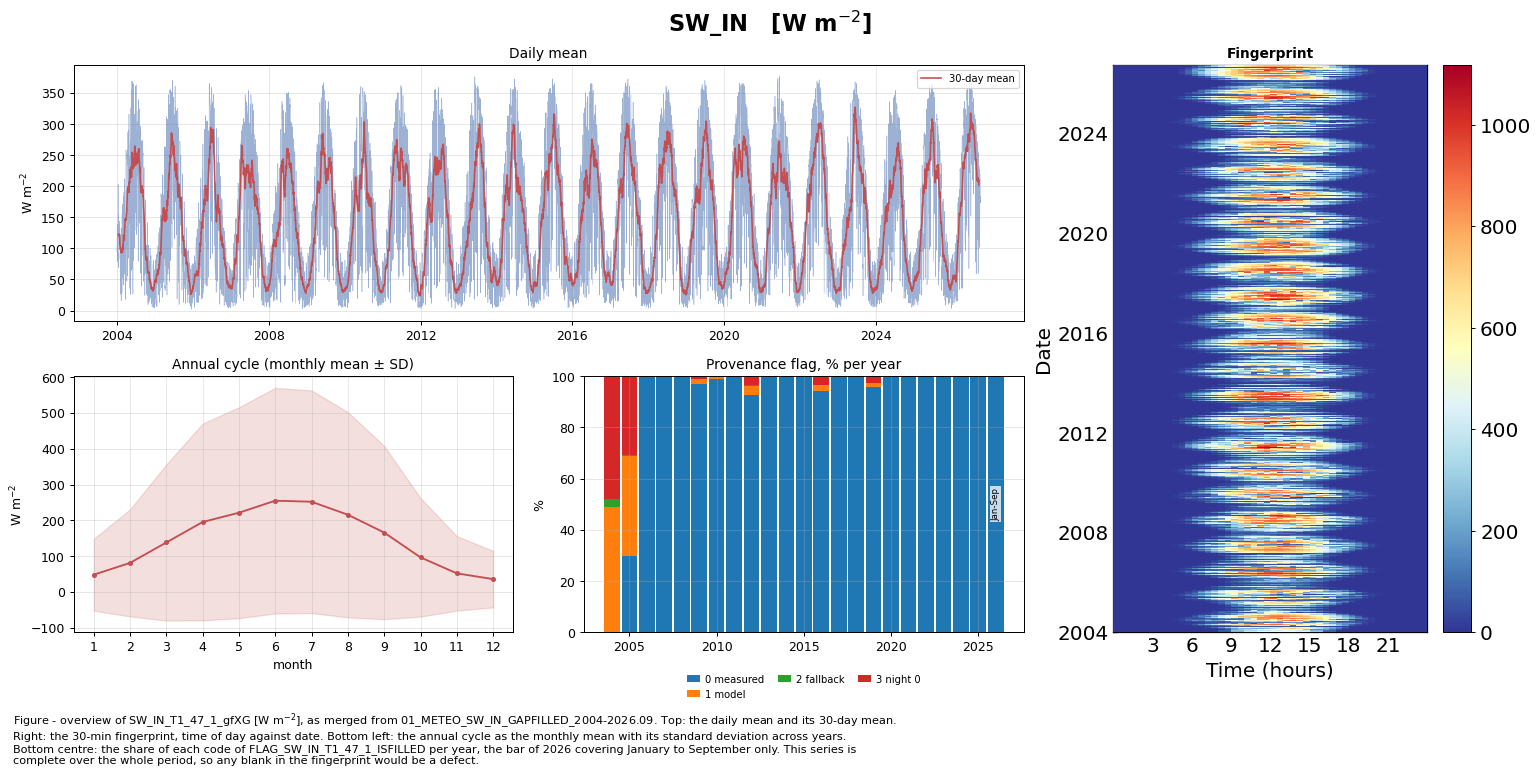

In [11]:
plot_product("SW_IN")

### 📊 Plot: `TA` — air temperature, measured

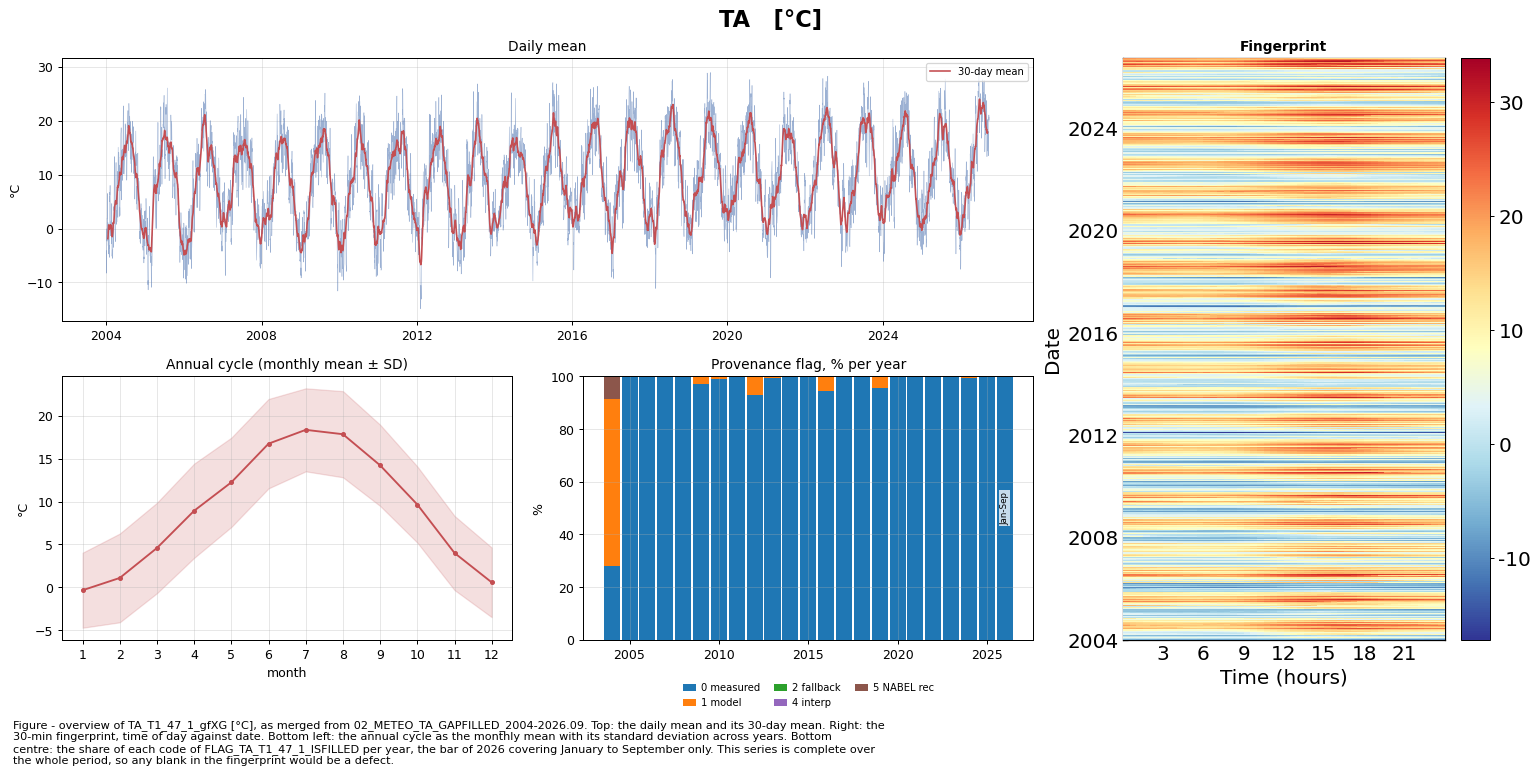

In [12]:
plot_product("TA")

### 📊 Plot: `TA_HOM` — air temperature, homogenised

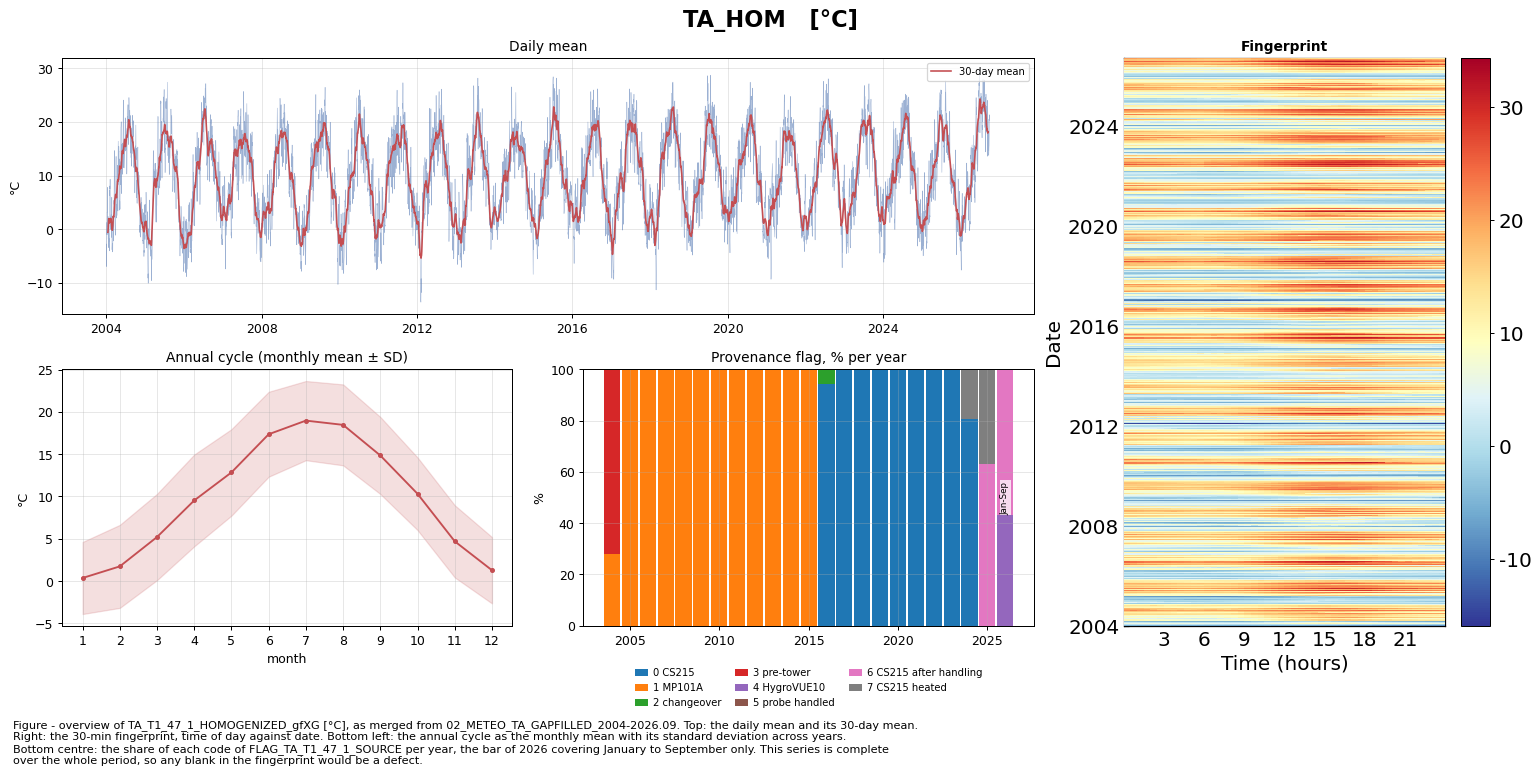

In [13]:
plot_product("TA_HOM")

### 📊 Plot: `PPFD_IN` — photosynthetic photon flux density

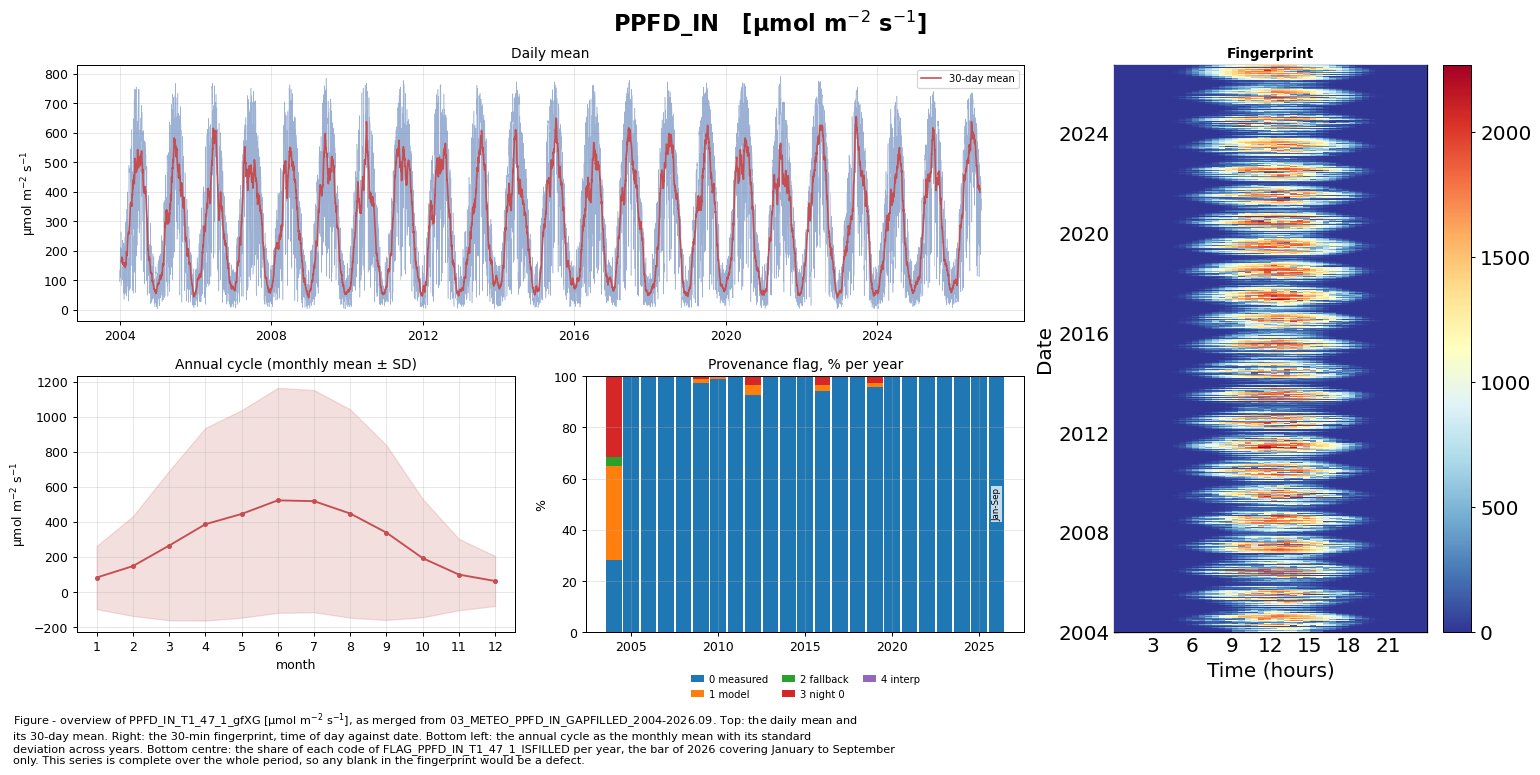

In [14]:
plot_product("PPFD_IN")

### 📊 Plot: `RH` — relative humidity, measured

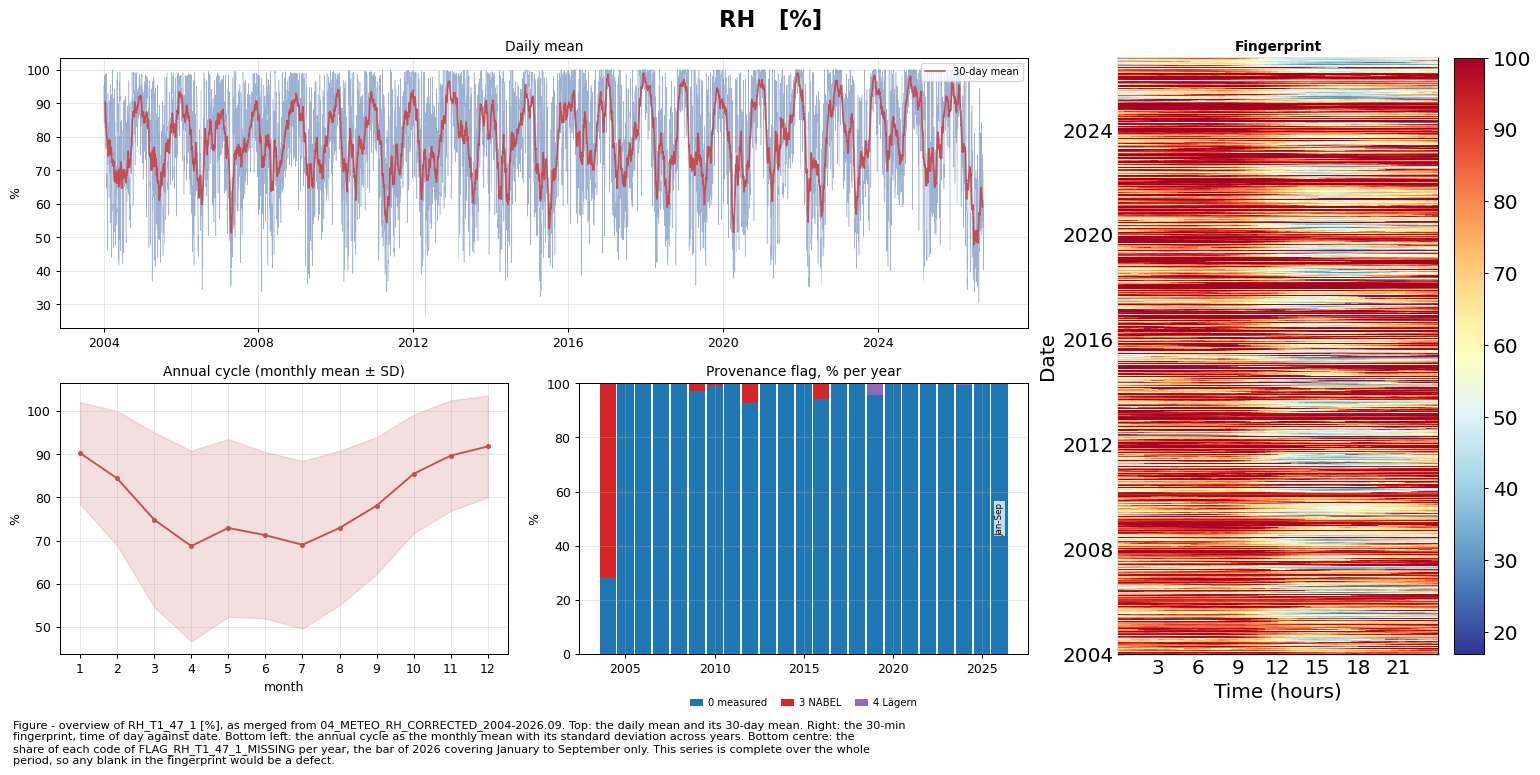

In [15]:
plot_product("RH")

### 📊 Plot: `RH_HOM` — relative humidity, homogenised

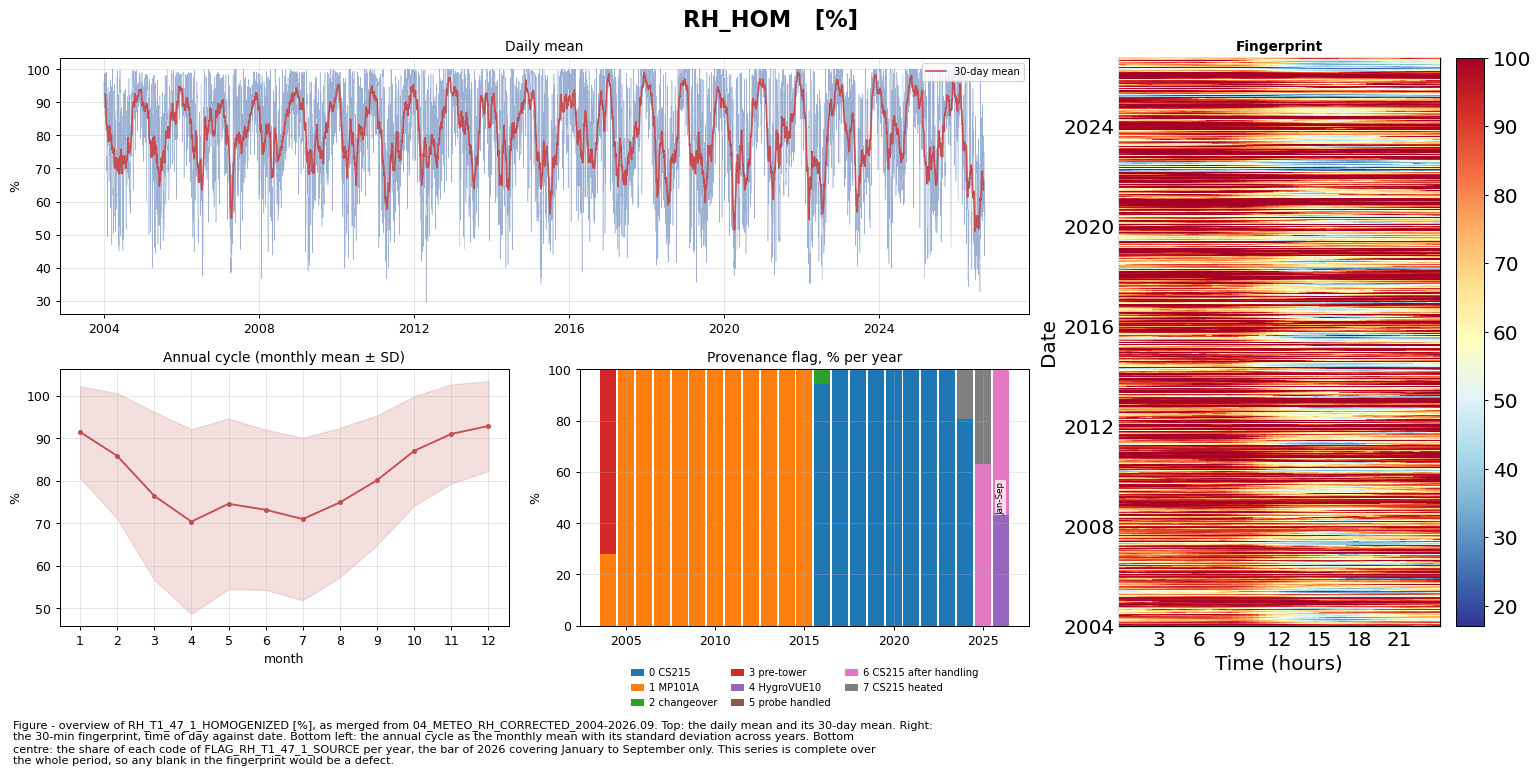

In [16]:
plot_product("RH_HOM")

### 📊 Plot: `PA` — air pressure

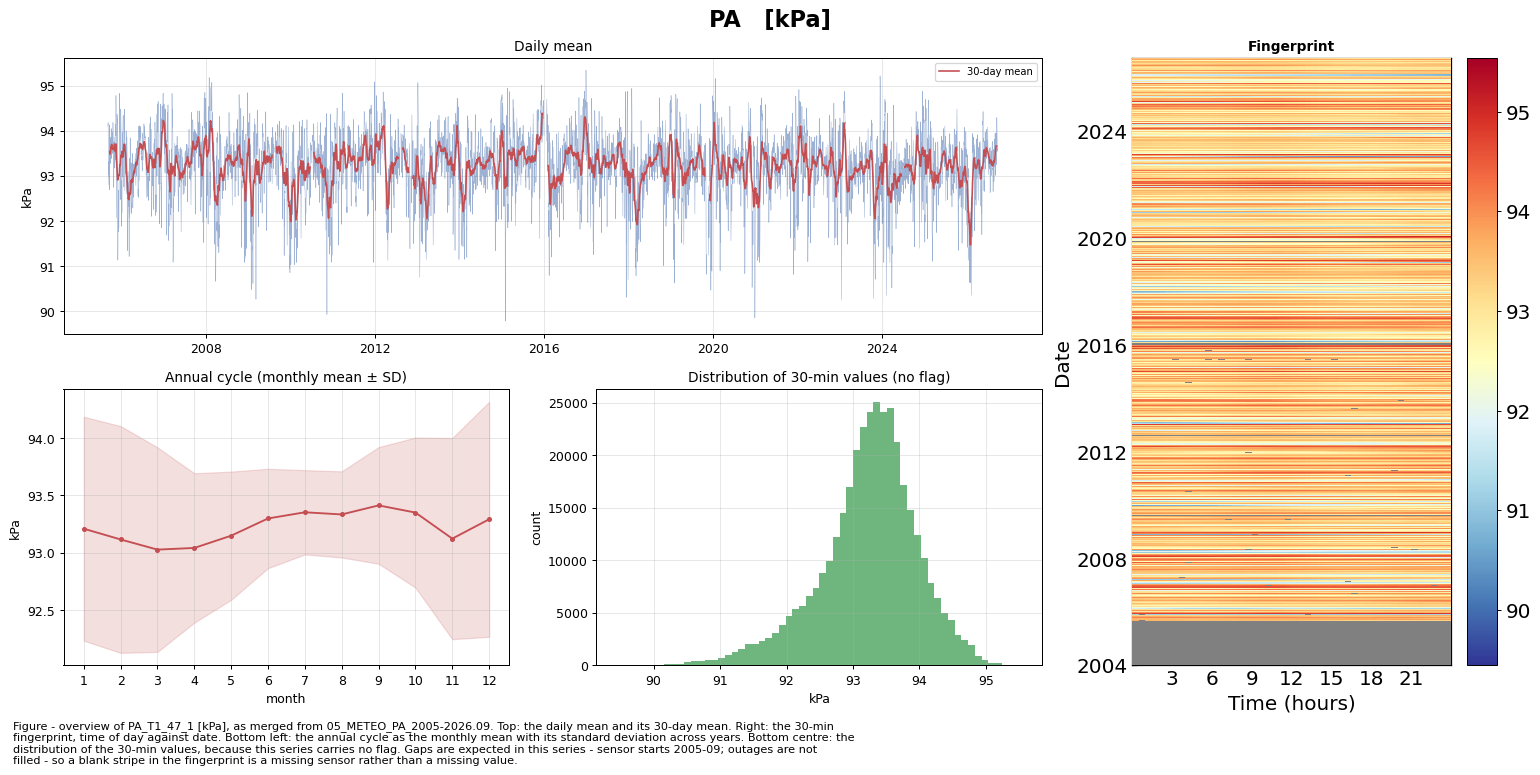

In [17]:
plot_product("PA")

### 📊 Plot: `LW_IN` — incoming longwave radiation

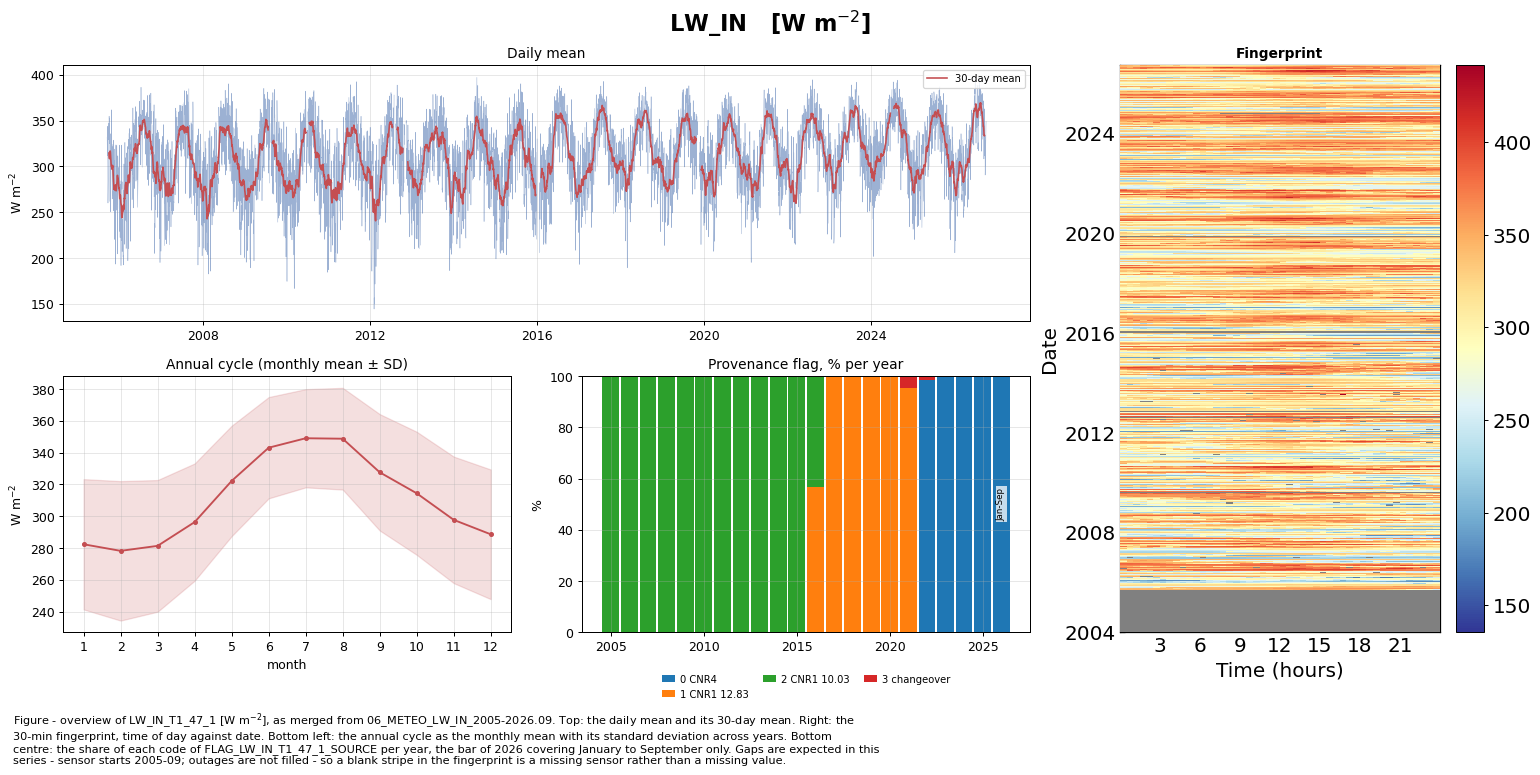

In [18]:
plot_product("LW_IN")

### 📊 Plot: `VPD` — vapour pressure deficit, measured

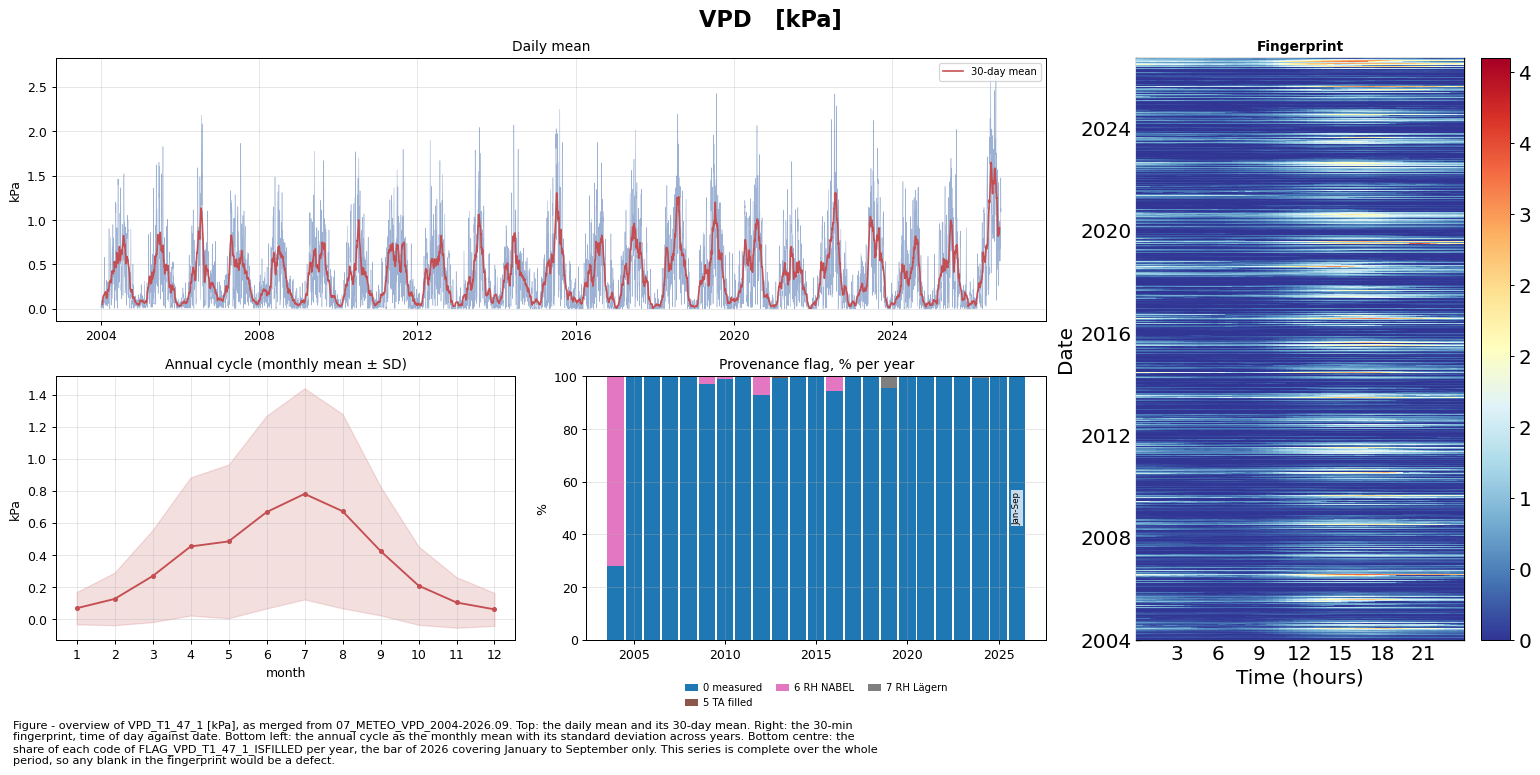

In [19]:
plot_product("VPD")

### 📊 Plot: `VPD_HOM` — vapour pressure deficit, homogenised

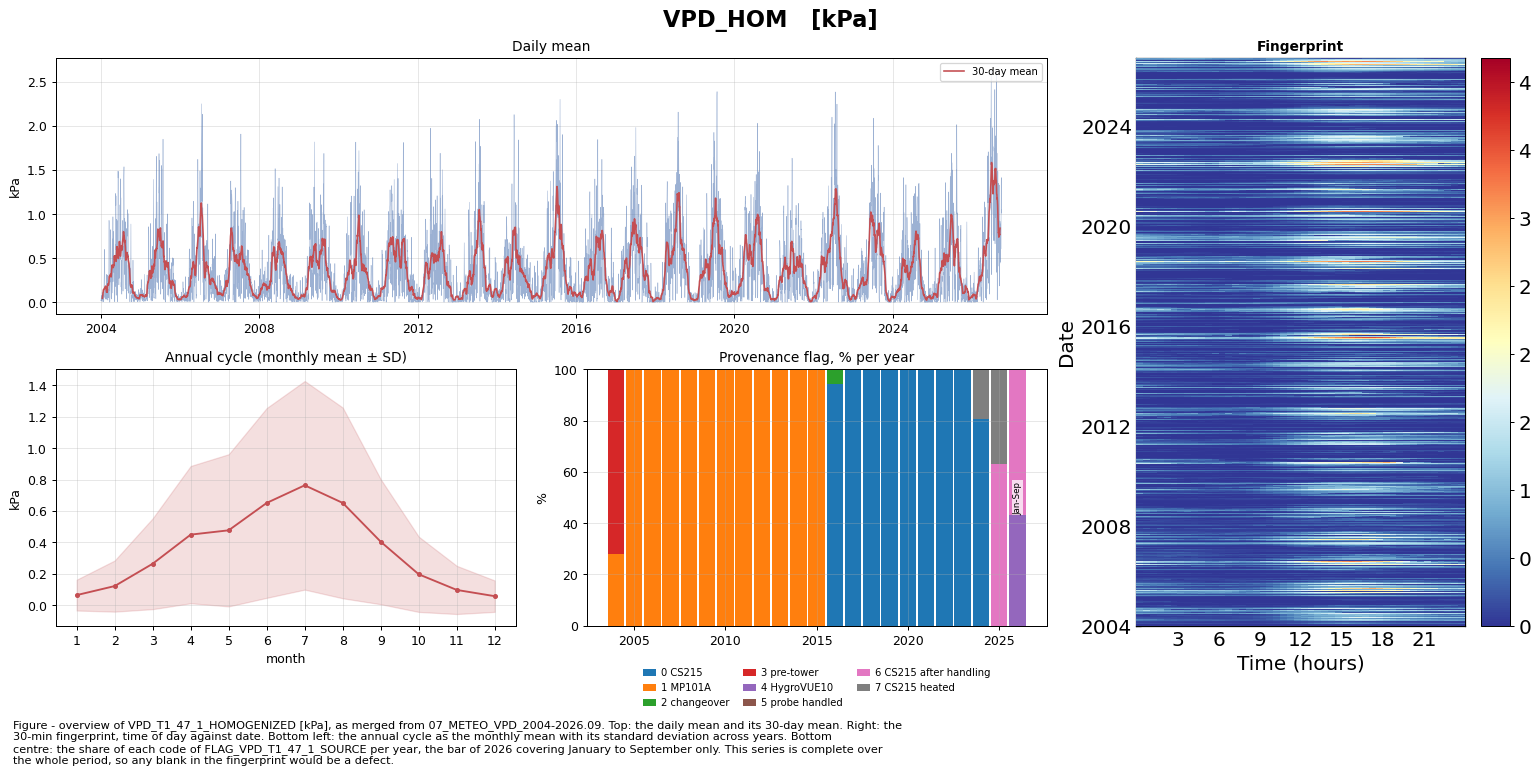

In [20]:
plot_product("VPD_HOM")

### All series accounted for

The figures above are written out one by one, so this asserts that no entry of `PRODUCTS`
lost its figure along the way.

In [21]:
_unplotted = [p[3] for p in PRODUCTS if p[3] not in PLOTTED]
assert not _unplotted, f"no figure cell for: {_unplotted}"
print(f"All {len(PLOTTED)} series in PRODUCTS have their own figure above.")


All 10 series in PRODUCTS have their own figure above.


***

In [22]:
print(f"Finished: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

Finished: 2026-10-23 14:27:38
